# §7 Experiments and Block Ablation

The model is used as a **measuring instrument** for the preparation decisions of §6: one estimator (L2
logistic regression, C frozen) is applied to every arm on the same stored folds, and each block is judged
against its locked hypothesis with paired intervals. Two populations get equal weight:

* **E-ALL** – the whole training part, label `L_comb` (84 % of the positives already know their diagnosis);
* **E-SCREEN** – people *not* told they have diabetes, positive = HbA1c ≥ 6.5 % (the screening use case).

The 20 % internal hold-out is kept out of all §7 fitting and scoring; its single use is §9.11, after `exp-freeze`.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, textwrap, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek

from IPython.display import display
pd.set_option("display.width", 150, "display.max_columns", 30, "display.max_colwidth", 60)


def show(df, digits=3):
    """Display a table as HTML (long text wraps; keeps the text output narrow)."""
    display(df.style.hide(axis="index").format(precision=digits, na_rep="")
            .set_properties(**{"text-align": "left", "white-space": "normal"}))


OUT = C.RESULTS_DIR / "S7"
OUT.mkdir(parents=True, exist_ok=True)
import os
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning")   # silence worker-side solver warnings (counted in run_arm_cv)
N_JOBS = min(12, max(1, (os.cpu_count() or 2) - 2))
# FAST mode (re-run setting) uses fewer coefficient-bootstrap replicates than config.N_BOOT_COEF: the unscaled arms
# reach the solver's iteration limit in every refit, which makes this the slowest step of the section. FINAL is unchanged.
B_COEF = C.N_BOOT_COEF if C.IS_FINAL else 30
S7 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_boot_coef": B_COEF}
T_START = time.time()
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, coefficient bootstrap B = {B_COEF}, {N_JOBS} workers")

mode FINAL: 5x5 CV, B = 1000, coefficient bootstrap B = 500, 12 workers


## 1 Splits
**Why.** Every arm must be scored on identical folds, otherwise paired differences mix model effects with
split noise. The hold-out (20 %, label × race stratified; created once at its first use in §6, DR-S6-12) and the
repeated stratified folds are stored with SHA-256 hashes and re-verified on every run. Folds are stratified on
the four label strata so that each fold holds a fair share of the 152 undiagnosed cases that define E-SCREEN.

In [2]:
# Rebuild the training part from the stored hold-out split and verify the stored repeated folds (§7.1).
# Reads the raw and labelled cohorts; produces X, y, esc, y_esc and folds; prints hashes. Hold-out rows are
# never scored.
raw = P.raw_cohort()
clean = L.add_labels(io.build_cohort())
# Guard: the raw (unprepared) and labelled cohorts must list the same people in the same order.
assert (raw["SEQN"].to_numpy() == clean["SEQN"].to_numpy()).all()
# The hold-out indices come from the stored split (created once); only the training part `tr` is used below.
tr, te = ek.make_holdout(clean)
raw_tr = raw.iloc[tr].reset_index(drop=True)
cl = clean.iloc[tr].reset_index(drop=True)
# Raw feature frames per feature tier; preparation steps are fitted later, inside each training fold.
X = {1: P.raw_feature_frame(raw_tr, 1), 2: P.raw_feature_frame(raw_tr, 2)}
# E-ALL target is L_comb; esc marks the E-SCREEN population (people not told they have diabetes).
y = cl["L_comb"].to_numpy()
esc = cl["in_escreen"].eq(1).to_numpy()
y_esc = cl["y_escreen"].fillna(0).astype(int).to_numpy()   # only scored inside the E-SCREEN mask
# Folds are stratified on the four label strata so the rare undiagnosed cases are spread over all folds.
strat = cl["stratum_3x3"].astype(str).to_numpy()
# Stored, hash-verified repeated stratified folds: every arm is scored on the same folds (paired comparisons).
folds = ek.make_folds(y, strat)
n = len(y)
# Train/test sizes of one fold; the Nadeau-Bengio variance correction needs them.
n_test_fold = n / C.CV_SPLITS
n_train_fold = n - n_test_fold
# Hold-out metadata is read only to print and store the hash of its test SEQNs, never to evaluate.
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
print(f"training part {n:,} rows ({y.sum()} L_comb positives); hold-out {len(te):,} rows - not evaluated in S7")
print(f"E-SCREEN in training part: {esc.sum():,} rows, {y_esc[esc].sum()} positives (HbA1c >= 6.5, not diagnosed)")
print(f"folds: {len(folds)} = {folds.n_splits} x {folds.n_repeats}, hash {folds.hash[:16]}..., file {folds.path.name}")
print(f"hold-out test SEQN SHA-256 {hold['sha256_test_seqn'][:16]}...")
# Positives per test fold in both populations: shows how few E-SCREEN cases each fold holds.
per_fold = pd.DataFrame([{"fold": i, "n_test": len(t), "pos_eall": int(y[t].sum()), "pos_escreen": int(y_esc[t][esc[t]].sum())}
                         for i, (_, t) in enumerate(folds)])
display(per_fold.describe().loc[["min", "mean", "max"], ["n_test", "pos_eall", "pos_escreen"]].round(1))
S7["splits"] = dict(n_train=n, n_holdout=len(te), n_pos_eall=int(y.sum()), n_escreen=int(esc.sum()),
                    n_pos_escreen=int(y_esc[esc].sum()), folds_hash=folds.hash, folds_file=folds.path.name,
                    holdout_sha256=hold["sha256_test_seqn"], pos_escreen_per_fold_min=int(per_fold["pos_escreen"].min()))

training part 4,584 rows (777 L_comb positives); hold-out 1,146 rows - not evaluated in S7
E-SCREEN in training part: 3,934 rows, 127 positives (HbA1c >= 6.5, not diagnosed)
folds: 25 = 5 x 5, hash 0d20f8f706ebf1e1..., file folds_FINAL.npz
hold-out test SEQN SHA-256 616fd0590bec7b92...


,n_test,pos_eall,pos_escreen
min,916.0,155.0,25.0
mean,916.8,155.4,25.4
max,917.0,156.0,26.0


**So what.** Each fold holds about 155 E-ALL positives but only about 24 E-SCREEN positives. E-SCREEN is
therefore scored on the pooled out-of-fold vector (paired bootstrap), not fold by fold, and most E-SCREEN
verdicts are expected to be inconclusive. The hold-out hash is printed so that §9.11 can show that the split and the file were unchanged
and that none of its rows were scored or fitted in §6–§9. (The §4/§5 diagnostics did use all adults; see §9.11.)

## 2 Data-justified model choice
**Why.** Only basic interpretable models are allowed (logistic regression and shallow trees). Within that constraint
each modelling choice is tied to a diagnostic number from the §4 model-justification table, with the reason for *not*
choosing the alternative.

In [3]:
# Read the stored §4 diagnostics (linearity, interactions, VIF) and tabulate which diagnostic justifies which
# choice (§7.2).
# Writes model_choice.csv; nothing is fitted here except the S design used to count parameters.
S4dir = C.RESULTS_DIR / "S4"
lin = pd.read_csv(S4dir / "linearity_tests.csv")
inter = pd.read_csv(S4dir / "interaction_tests.csv")
daj = pd.read_csv(S4dir / "daj_table.csv")
vif4 = pd.read_csv(S4dir / "vif_table.csv")
print("§4 RCS linearity tests (4 knots vs linear, df 2):")
display(lin[["label", "n", "n_events", "chi2", "p", "nonlinear"]].round(4))
print("§4 interaction tests (primary spec A):")
display(inter[inter["spec"] == "A_primary"][["term", "chi2", "df", "p", "verdict"]].round(4))
# Sex x BMI p-value in every specification, printed rather than summarised.
sx = inter[inter["term"] == "sex_x_bmi"].set_index("spec")["p"].round(3).to_dict()
# Parameters of the S arm after preparation: columns of the fitted transformer (final estimator dropped).
epv_den = {t: P.build_pipeline(P.ARMS["S"], t)[:-1].fit_transform(X[t]).shape[1] for t in (1, 2)}
# Events per parameter (EPV) = positives / parameters, a rule of thumb for overfitting risk.
epv = {t: round(y.sum() / k, 1) for t, k in epv_den.items()}
print(f"\nsex x BMI by spec: {sx}")
print(f"events per parameter in S: Tier 1 {y.sum()}/{epv_den[1]} = {epv[1]}, Tier 2 {y.sum()}/{epv_den[2]} = {epv[2]}")
print(f"imbalance: prevalence {y.mean():.3f} in the training part")
lin_i = lin.set_index("variable")
# Variables quoted as evidence for non-linearity.
nl = ["RIDAGEYR", "BMXBMI", "LBDHDD", "LBXTC"]
ia = inter[inter["spec"] == "A_primary"].set_index("term")
# VIFs of raw weight/height/BMI/waist and of the six blood-pressure readings: evidence for collinearity
# handling.
vr = vif4[vif4["set"] == "raw_anthropometry"].set_index("variable")["vif"]
vb = vif4.loc[vif4["set"] == "bp_readings", "vif"]
ev_nonlin = ", ".join(f"{lin_i.loc[v, 'label']} {lin_i.loc[v, 'chi2']:.1f}" for v in nl) + f" (all p < {lin_i.loc[nl, 'p'].max():.3f})"
ev_inter = (f"race x BMI p {ia.loc['race_x_bmi', 'p']:.2f}, Asian x BMI p {ia.loc['asian_x_bmi', 'p']:.2f} "
            f"(MDE {ia.loc['asian_x_bmi', 'mde']:.2f} log-OR)")
ev_coll = f"weight VIF {vr['BMXWT']:.1f}, BMI {vr['BMXBMI']:.1f}; 6 BP readings {vb.min():.1f}-{vb.max():.1f}"
# One row per modelling question: evidence, decision, and why the alternative was rejected.
choice = pd.DataFrame([
    ("non-linearity", ev_nonlin, "L2 logistic regression + B-spline basis (P13)", "categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"),
    ("interactions", ev_inter, "no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)", "interaction terms add variance without detectable gain"),
    ("collinearity", ev_coll, "aggregate + in-fold VIF pruning (P04/P05), L2 as second defence", "L1 (unstable selection among collinear columns, sensitivity only)"),
    ("sample size", f"{y.sum()} events / {epv_den[1]} parameters (EPV {epv[1]})", "unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV", "deep trees / ensembles (overfit, outside the allowed model class)"),
    ("imbalance", f"prevalence {y.mean():.1%}", "no resampling; class_weight tested as block B6a", "SMOTE (breaks calibration and the survey design)"),
    ("thresholds / leakage", "clinical cut-points and leakage need inspection", "depth-3 tree (min leaf 50) as a probe only", "tree as main model (step functions, unstable)"),
], columns=["diagnostic", "evidence (S4 / S7)", "decision", "why not the alternative"])
choice.to_csv(OUT / "model_choice.csv", index=False)
show(choice)
S7["model_choice"] = dict(linearity=lin.set_index("label")[["chi2", "p"]].round(4).to_dict("index"),
                          sex_x_bmi_p_by_spec=sx, epv=epv, n_params=epv_den)

§4 RCS linearity tests (4 knots vs linear, df 2):


,label,n,n_events,chi2,p,nonlinear
0,age,4478,722,57.6075,0.0000,True
1,BMI,4478,722,11.5618,0.0031,True
2,waist,4478,722,7.0540,0.0294,True
3,SBP (mean),4478,722,5.8698,0.0531,False
4,HDL,4478,722,18.4670,0.0001,True
5,total cholesterol,4478,722,41.7673,0.0000,True
6,PIR,4478,722,0.8344,0.6589,False


§4 interaction tests (primary spec A):


,term,chi2,df,p,verdict
0,race_x_bmi,5.1890,5,0.3933,not detected
1,asian_x_bmi,0.0071,1,0.9328,not detected
2,age_x_bmi,0.5829,1,0.4452,not detected
3,sex_x_bmi,6.9951,1,0.0082,detected



sex x BMI by spec: {'A_primary': 0.008, 'B_minimal': 0.833, 'C_splines': 0.072}
events per parameter in S: Tier 1 777/42 = 18.5, Tier 2 777/53 = 14.7
imbalance: prevalence 0.170 in the training part


diagnostic,evidence (S4 / S7),decision,why not the alternative
non-linearity,"age 57.6, BMI 11.6, HDL 18.5, total cholesterol 41.8 (all p < 0.003)",L2 logistic regression + B-spline basis (P13),"categorised bands (arbitrary cut-points, information loss); GAM / boosting (outside the allowed model class)"
interactions,"race x BMI p 0.39, Asian x BMI p 0.93 (MDE 0.70 log-OR)","no interaction terms; Asian BMI bias treated as a measurement issue (P14, S8)",interaction terms add variance without detectable gain
collinearity,"weight VIF 95.7, BMI 97.6; 6 BP readings 8.8-11.7","aggregate + in-fold VIF pruning (P04/P05), L2 as second defence","L1 (unstable selection among collinear columns, sensitivity only)"
sample size,777 events / 42 parameters (EPV 18.5),unpenalised fit would be acceptable; mild L2 (C0) chosen by inner CV,"deep trees / ensembles (overfit, outside the allowed model class)"
imbalance,prevalence 17.0%,no resampling; class_weight tested as block B6a,SMOTE (breaks calibration and the survey design)
thresholds / leakage,clinical cut-points and leakage need inspection,depth-3 tree (min leaf 50) as a probe only,"tree as main model (step functions, unstable)"


**So what.** Age, BMI and both lipids bend significantly, so the main model uses spline terms; the linear version
stays as the ablation arm *S-linear*. Race × BMI and Asian × BMI are not detected (underpowered: "not detected" is
not "absent"). Sex × BMI is significant in §4's primary specification only (p by specification printed above), so
no interaction term is added and the point is a limitation. With about 18 events per parameter overfitting risk is
modest; L2 mainly stabilises the correlated anthropometrics. In-fold VIF > 10 pruning with BMI and waist protected
(P05) removes only weight (§6.5).

## 3 Regularisation strength C0
**Why.** A fair minimal-versus-systematic comparison requires the *same model* in every arm. C is therefore chosen once – by
`LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10])`, inner 5-fold ROC-AUC, on the S arm of Tier 1 with its class and
survey weights – and then frozen for every arm. Choosing it on S favours S slightly (the other arms do not get
their own tuning); M0 and M1 with their own C are a §9.4 sensitivity. C0 was chosen once on the training part and is
*not* nested inside the outer folds; a nested check is reported in §9 (post-audit corrections).

In [4]:
# Choose the L2 strength C0 once, by inner 5-fold CV on the S arm (Tier 1), and freeze it for all arms (§7.3).
# Reads the training part; produces C0 and the inner-CV AUC per candidate C (stored with the section results).
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold

# Design matrix of the S arm after its preparation steps (final estimator dropped); label and weights follow.
cfgS = P.ARMS["S"]
design = P.build_pipeline(cfgS, 1)[:-1].fit_transform(X[1])
ylab = P.training_label(raw_tr, cfgS)
# Inner splitter seeded from the master seed, so the choice of C0 is reproducible.
inner = StratifiedKFold(5, shuffle=True, random_state=ek.derive_seed(C.SEED_MASTER, "S7", "C0"))
# Pure L2 via l1_ratios=(0.0,); class weights and survey weights match how the S arm is fitted.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    lrcv = LogisticRegressionCV(Cs=[0.01, 0.1, 1, 10], cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                class_weight="balanced", l1_ratios=(0.0,), use_legacy_attributes=False)
    lrcv.fit(design, ylab, sample_weight=P.survey_weights(raw_tr))
scores = np.asarray(lrcv.scores_).reshape(5, -1)   # (inner folds, Cs); l1_ratio fixed at 0 (pure L2)
# Selected C (a single value because l1_ratio is fixed at 0).
C0 = float(np.ravel(lrcv.C_)[0])
# Mean inner-CV AUC for each candidate C, to judge how sensitive results are to the penalty.
cv_auc = pd.Series(scores.mean(axis=0).ravel()[:4], index=[0.01, 0.1, 1, 10]).round(4)
print("inner-CV ROC-AUC by C:"); print(cv_auc.to_string())
print(f"C0 = {C0} (frozen for all arms and tiers)")
S7["C0"] = dict(C0=C0, inner_cv_auc=cv_auc.to_dict())

inner-CV ROC-AUC by C:
0.01     0.8490
0.10     0.8519
1.00     0.8515
10.00    0.8514
C0 = 0.1 (frozen for all arms and tiers)


**So what.** The inner-CV AUC is almost flat across C (range about 0.003), so C is not a lever for the results below
and the optimism of tuning on S is expected to be small. Disclosure: C0 was chosen once on the whole training part
(the S-arm preparation steps were fitted on all of it for this one choice), not nested inside the outer folds.
The flat curve suggests the optimism is small; the nested check in §9 (post-audit corrections) tests this.

## 4 Running the arms
**Why.** Each arm × tier is cross-validated on the stored folds with the frozen C0; every preparation step is
refitted inside each training fold. Arms with P02 off are trained on their own naive label (965 positives),
but every arm is scored against the frozen `L_comb`. The depth-3 tree is run on M0, M1 and S as a probe.
Solver non-convergence (the unscaled arms) is counted, not suppressed.

In [5]:
# Cross-validate every arm x tier x model on the stored folds with the frozen C0 (§7.4), in parallel workers.
# Produces OOF (out-of-fold predictions per run), PM (repeat-averaged probability per row) and convergence
# counts.
ARM_LIST = list(P.ARMS)
# Logistic regression for every arm in both tiers; the depth-3 tree probe only for M0, M1 and S.
jobs = [(a, t, "lr") for t in (1, 2) for a in ARM_LIST] + [(a, t, "tree") for t in (1, 2) for a in ("M0", "M1", "S")]
t0 = time.time()
# one job per arm x tier x model, each deterministic: the number of workers changes the wall time only (FAST may use
# every core so that the re-run stays within about 5 minutes; FINAL keeps its worker count)
N_JOBS_ARMS = N_JOBS if C.IS_FINAL else max(N_JOBS, (os.cpu_count() or 2) - 2)
# run_arm_cv refits every preparation step inside each training fold, so the test fold never informs
# preparation.
runs = Parallel(n_jobs=N_JOBS_ARMS)(delayed(P.run_arm_cv)(a, t, X[t], raw_tr, folds, C_=C0, model=m) for a, t, m in jobs)
# OOF[(arm, tier, model)] is a long table of out-of-fold probabilities with repeat, fold and row indices.
OOF = {(r["arm"], r["tier"], r["model"]): r["oof"] for r in runs}
PM = {k: ek.mean_oof(v, n) for k, v in OOF.items()}          # repeat-averaged OOF probability per row
diag = pd.DataFrame([{k: r[k] for k in ("arm", "tier", "model", "n_convergence_warnings", "seconds", "n_pos_train_label")}
                     for r in runs])
# Guard: every row received a finite prediction in every run.
assert all(np.isfinite(v).all() for v in PM.values())
for r in runs:   # no hold-out row can appear: OOF rows index the training part only
    assert r["oof"]["row"].max() < n and r["oof"].groupby("repeat")["row"].nunique().eq(n).all()
print(f"{len(jobs)} arm x tier x model runs, {sum(len(f) for f in [folds]) * len(jobs)} fits, {time.time() - t0:.0f} s wall")
print("runs with solver non-convergence (folds at the iteration limit):")
display(diag[diag["n_convergence_warnings"] > 0].round(1))
S7["runs"] = dict(n_runs=len(jobs), wall_seconds=time.time() - t0,
                  convergence=diag[diag["n_convergence_warnings"] > 0][["arm", "tier", "model", "n_convergence_warnings"]].to_dict("records"))

44 arm x tier x model runs, 1100 fits, 108 s wall
runs with solver non-convergence (folds at the iteration limit):


,arm,tier,model,n_convergence_warnings,seconds,n_pos_train_label
0,M0,1,lr,25,60.7,772
1,M1,1,lr,25,43.9,772
3,cum+B1,1,lr,25,43.0,777
4,cum+B3,1,lr,25,39.4,777
5,cum+B4,1,lr,25,40.5,777
12,S-B5,1,lr,25,39.2,777
19,M0,2,lr,24,65.2,772
20,M1,2,lr,25,51.8,772
22,cum+B1,2,lr,25,50.6,777
23,cum+B3,2,lr,25,45.8,777


In [6]:
# Population masks, metric functions and one result row per run: AUC with bootstrap CI, PR-AUC, Brier,
# calibration.
# Writes arm_metrics.csv; E-ALL and E-SCREEN are scored on the pooled (repeat-averaged) OOF vectors.
from sklearn.metrics import roc_auc_score, average_precision_score

def pop_of(name):
    """(label vector, evaluation mask) of a population."""
    if name == "E-ALL":
        return y, np.ones(n, bool)
    if name == "E-SCREEN":
        return y_esc, esc
    if name == "PIR-missing":
        return y, cl["INDFMPIR"].isna().to_numpy()
    raise ValueError(name)

# Balanced accuracy at a fixed 0.5 probability threshold (shows what class weights do to a threshold).
def _bacc05(yy, pp):
    pred = pp >= 0.5
    return 0.5 * (pred[yy == 1].mean() + (~pred[yy == 0]).mean())

# Absolute distance of the calibration slope from its ideal value of 1 (smaller is better).
def _calslope_dev(yy, pp):
    return abs(ek._calibration(yy, pp)[0] - 1.0)

# Metric registry shared by the comparison engine (bootstrap and per-fold values).
METRIC_FN = {"roc_auc": roc_auc_score, "pr_auc": average_precision_score,
             "brier": lambda yy, pp: float(np.mean((pp - yy) ** 2)),
             "bacc05": _bacc05, "calslope_dev": _calslope_dev}

def auc_ci(p, pop="E-ALL", seed_tag="auc"):
    """AUC of a pooled OOF vector with a label-stratified bootstrap CI (paired against a constant 0.5)."""
    yy, m = pop_of(pop)
    # Comparing against a constant 0.5 prediction makes the paired bootstrap return the plain AUC; 0.5 is
    # added back.
    b = ek.paired_bootstrap(yy, p, np.full(n, 0.5), "roc_auc", n_boot=C.N_BOOT, eval_mask=m,
                            seed=ek.derive_seed(C.SEED_MASTER, "S7", seed_tag, pop))
    return b["metric_a"], b["ci_low"] + 0.5, b["ci_high"] + 0.5

# One result row per run: fold-level AUC mean and SD, plus pooled-OOF metrics in both populations.
def arm_row(key):
    oof, pm = OOF[key], PM[key]
    # Per-fold AUC on E-ALL: its mean and SD show how much the split alone moves the metric.
    fm = ek.fold_metrics(oof, y)
    out = {"arm": key[0], "tier": key[1], "model": key[2], "eall_auc_foldmean": fm["roc_auc"].mean(),
           "eall_auc_foldsd": fm["roc_auc"].std(ddof=1)}
    for pop in ("E-ALL", "E-SCREEN"):
        yy, m = pop_of(pop)
        # Metric suite on the repeat-averaged probabilities, restricted to the population mask.
        ms = ek.metric_suite(yy[m], pm[m])
        a, lo, hi = auc_ci(pm, pop, seed_tag=f"{key}")
        tag = "eall" if pop == "E-ALL" else "escr"
        out.update({f"{tag}_auc": a, f"{tag}_auc_lo": lo, f"{tag}_auc_hi": hi, f"{tag}_pr_auc": ms["pr_auc"],
                    f"{tag}_brier": ms["brier"], f"{tag}_recall_spec80": ms["recall_at_spec"],
                    f"{tag}_cal_slope": ms["cal_slope"], f"{tag}_cal_citl": ms["cal_citl"], f"{tag}_prev": ms["prevalence"]})
    # Survey-weighted AUC (WTPH2YR) as a check on the unweighted headline.
    out["eall_auc_weighted"] = ek.metric_suite(y, pm, w=cl[C.WEIGHT_PHLEB].to_numpy())["roc_auc"]
    return out

# The merge attaches solver-convergence counts and timing to each run.
arm_metrics = pd.DataFrame([arm_row(k) for k in OOF]).merge(diag, on=["arm", "tier", "model"])
arm_metrics.to_csv(OUT / "arm_metrics.csv", index=False)
cols_show = ["arm", "model", "eall_auc", "eall_auc_lo", "eall_auc_hi", "escr_auc", "escr_auc_lo", "escr_auc_hi",
             "eall_brier", "escr_recall_spec80", "eall_cal_slope", "n_convergence_warnings"]
# Arms shown in the headline table; all arms and Tier 2 are in the CSV.
main_arms = ["M0", "M1", "S", "T1-minus-care", "S-linear", "S+WHtR"]
tab = arm_metrics[(arm_metrics["tier"] == 1) & arm_metrics["arm"].isin(main_arms)]
print("Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):")
display(tab[cols_show].round(3))

Tier 1, main arms (all arms and Tier 2: results/S7/arm_metrics.csv):


,arm,model,eall_auc,eall_auc_lo,eall_auc_hi,escr_auc,escr_auc_lo,escr_auc_hi,eall_brier,escr_recall_spec80,eall_cal_slope,n_convergence_warnings
0,M0,lr,0.961,0.952,0.968,0.844,0.808,0.881,0.040,0.709,1.195,25
1,M1,lr,0.828,0.814,0.843,0.772,0.739,0.804,0.112,0.535,0.961,25
2,S,lr,0.836,0.822,0.849,0.781,0.748,0.809,0.185,0.520,0.867,0
15,T1-minus-care,lr,0.820,0.806,0.835,0.800,0.766,0.832,0.195,0.614,0.873,0
16,S-linear,lr,0.832,0.817,0.845,0.775,0.744,0.806,0.189,0.496,0.849,0
18,S+WHtR,lr,0.835,0.822,0.848,0.782,0.751,0.814,0.186,0.551,0.866,0
38,M0,tree,0.927,0.912,0.941,0.633,0.574,0.689,0.031,0.441,1.239,0
39,M1,tree,0.766,0.748,0.782,0.701,0.663,0.740,0.123,0.433,1.021,0
40,S,tree,0.768,0.751,0.784,0.683,0.646,0.720,0.190,0.354,0.963,0


**So what.** The paired comparisons below decide; three patterns are already visible. The naive arm M0 reaches
an E-ALL AUC near 0.96 that collapses once the availability rule is applied; all admissible arms sit in a narrow
band; and every arm loses discrimination on E-SCREEN. Only the unscaled arms (M0, M1, the cumulative steps before
B5, S−B5) stop at the solver's iteration limit – a cost of skipping scaling, examined post lock in §7.12.1.

### Comparison engine
Paired difference A − B of a metric on a population: fold-level Nadeau–Bengio corrected t and a paired,
label-stratified bootstrap on the repeat-averaged OOF vectors; on E-ALL the **wider** interval is used, on
E-SCREEN the bootstrap only. The estimate is always the same quantity per population: on E-ALL the mean of the
fold-level paired differences, on E-SCREEN the difference on the pooled OOF vector. The 80 %-power minimal detectable difference (MDD) is reported with each Δ. Verdict
rules are those locked in `governance/hypotheses.md`; for a directional claim an `evalkit` verdict of
"equivalent" (CI inside ±magnitude) means the claimed magnitude is excluded and is recorded as **refuted**.

In [7]:
# Comparison engine (§7.4.1): paired difference A - B with Nadeau-Bengio corrected t and a paired bootstrap,
# plus verdict helpers.
# Produces no results itself; later cells call cmp_(), and COMP collects every comparison row.
# Metric value per (repeat, fold) test set, restricted to the population mask: the input of the corrected
# t-test.
def fold_values(key, metric, pop):
    yy, m = pop_of(pop)
    fn = METRIC_FN[metric]
    vals = {}
    for (r, f), g in OOF[key].groupby(["repeat", "fold"]):
        rows = g["row"].to_numpy()
        keep = m[rows]
        vals[(r, f)] = fn(yy[rows][keep], g["prob"].to_numpy()[keep])
    return pd.Series(vals)

def compare(a, b, tier=1, metric="roc_auc", pop="E-ALL", model="lr", pa=None, pb=None):
    """Paired comparison A - B; pa/pb override the OOF vectors (baselines)."""
    yy, m = pop_of(pop)
    # pa/pb override the OOF vectors, so baselines that are not in OOF (e.g. ADA points) use the same engine.
    pa = PM[(a, tier, model)] if pa is None else pa
    pb = PM[(b, tier, model)] if pb is None else pb
    # The bootstrap knows AUC, Brier and PR-AUC by name; other metrics are passed as functions.
    bm = metric if metric in ("roc_auc", "brier", "pr_auc") else METRIC_FN[metric]
    # Seed derived from arms, tier, metric and population: each comparison is reproducible and independent.
    bs = ek.paired_bootstrap(yy, pa, pb, bm, n_boot=C.N_BOOT, eval_mask=m,
                             seed=ek.derive_seed(C.SEED_MASTER, "S7", a, b, tier, metric, pop))
    row = dict(a=a, b=b, tier=tier, metric=metric, pop=pop, model=model, diff_pooled=bs["diff"],
               boot_lo=bs["ci_low"], boot_hi=bs["ci_high"], boot_se=bs["se"], n_eval=bs["n_eval"], n_pos=bs["n_pos"])
    # The fold-level test needs fold predictions, so it is skipped on E-SCREEN (too few positives per fold).
    if pop != "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
        # Paired per-fold differences; the J = repeats x folds values are dependent, so the variance needs a
        # correction.
        d = (fold_values((a, tier, model), metric, pop) - fold_values((b, tier, model), metric, pop)).to_numpy()
        # Nadeau-Bengio correction: variance factor (1/J + n_test/n_train) instead of 1/J, because CV training
        # sets overlap.
        ct = ek.corrected_t(d, n_train_fold, n_test_fold)
        row.update(t_mean=ct["mean"], t_lo=ct["ci_low"], t_hi=ct["ci_high"], t_se=ct["se_corr"], t_p=ct["p"], J=ct["J"])
        # Conservative rule on E-ALL: use the wider of the corrected-t and bootstrap intervals.
        use_t = (ct["ci_high"] - ct["ci_low"]) >= (bs["ci_high"] - bs["ci_low"])
        lo, hi, se = (ct["ci_low"], ct["ci_high"], ct["se_corr"]) if use_t else (bs["ci_low"], bs["ci_high"], bs["se"])
        est = ct["mean"]   # one estimand on E-ALL: the fold-mean paired difference (interval = the wider of the two)
        # Minimal detectable difference at 80 % power, two-sided 5 %: (t_0.975 + t_0.80) * SE.
        mdd = (stats.t.ppf(0.975, ct["df"]) + stats.t.ppf(0.80, ct["df"])) * se
        row["interval"] = "corrected_t" if use_t else "bootstrap"
    else:
        # E-SCREEN and fold-less baselines: bootstrap interval only, normal quantiles for the MDD.
        est, lo, hi, se = bs["diff"], bs["ci_low"], bs["ci_high"], bs["se"]
        mdd = (stats.norm.ppf(0.975) + stats.norm.ppf(0.80)) * se
        row["interval"] = "bootstrap"
        # Per-repeat differences show how much the E-SCREEN result depends on a particular CV repeat.
        if pop == "E-SCREEN" and (a, tier, model) in OOF and (b, tier, model) in OOF:
            ra = ek.repeat_metrics(OOF[(a, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            rb = ek.repeat_metrics(OOF[(b, tier, model)], y_esc, eval_mask=esc).set_index("repeat")
            if metric in ra:
                dr = ra[metric] - rb[metric]
                row.update(rep_min=dr.min(), rep_max=dr.max())
    row.update(est=est, lo=lo, hi=hi, se=se, mdd=mdd)
    return row

# Equivalence verdict for margin s: supported if the whole CI is inside ±s, refuted if it lies fully outside.
def v_equiv(lo, hi, s):
    return "supported" if (lo > -s and hi < s) else ("refuted" if (lo >= s or hi <= -s) else "inconclusive")

# Directional verdict from evalkit; 'equivalent' excludes the claimed magnitude and is recorded as refuted.
def v_dir(lo, hi, est, s, direction):
    v = ek.verdict(lo, hi, s, direction, est)
    return "refuted" if v == "equivalent" else v

# Non-inferiority verdict: supported if the lower bound stays above -s, refuted if the upper bound is below
# -s.
def v_noninf(lo, hi, s):
    return "supported" if lo > -s else ("refuted" if hi < -s else "inconclusive")

COMP = []   # every comparison row, stored in results/S7/comparisons.csv

# Run a comparison, label it and store its row for comparisons.csv.
def cmp_(*args, label="", **kw):
    r = compare(*args, **kw)
    r["label"] = label
    COMP.append(r)
    return r

# Format a comparison row as 'estimate [CI] (interval used, MDD)'.
def fmt(r, k=3):
    return f"{r['est']:+.{k}f} [{r['lo']:+.{k}f}, {r['hi']:+.{k}f}] ({r['interval']}, MDD {r['mdd']:.{k}f})"

## 5 Leak gate: M0 → M1
**Why.** M0 keeps glucose, treatment, diagnosis history, prediabetes counselling (DIQ160) and prior glucose
testing (DIQ180). If the availability rule removes real leakage, discrimination must *drop* – a correct
deterioration (hypotheses H2a, B2). A depth-3 tree shows *where* the M0 signal comes from (B2t).

Tier 1 E-ALL    AUC M1 - M0 = -0.131 [-0.148, -0.114] (corrected_t, MDD 0.024)


Tier 1 E-SCREEN AUC M1 - M0 = -0.072 [-0.113, -0.031] (bootstrap, MDD 0.059)


Tier 2 E-ALL    AUC M1 - M0 = -0.119 [-0.133, -0.106] (corrected_t, MDD 0.019)


Tier 2 E-SCREEN AUC M1 - M0 = -0.081 [-0.120, -0.041] (bootstrap, MDD 0.056)


Tier 1 E-ALL    AUC S - (S-B2) = -0.122 [-0.138, -0.105] (corrected_t, MDD 0.023)


Tier 1 E-SCREEN AUC S - (S-B2) = -0.090 [-0.124, -0.060] (bootstrap, MDD 0.047)


arm,root_feature,variable,role,threshold,level2
M0,DIQ070_2.0,DIQ070,leak,0.500,"['DIQ180_2.0', 'DID040']"
M1,BPQ020_2.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"
S,BPQ020_1.0,BPQ020,feature,0.500,"['BMXWAIST', 'BMXWAIST']"


|--- taking diabetic pills: no <= 0.50
|   |--- blood-glucose test in past 3 years: no <= 0.50
|   |   |--- weights: [43.00, 17.00] class: 0
|   |--- blood-glucose test in past 3 years: no >  0.50
|   |   |--- LDL cholesterol (mg/dL) <= 119.50
|   |   |   |--- weights: [0.00, 430.00] class: 1
|   |   |--- LDL cholesterol (mg/dL) >  119.50
|   |   |   |--- weights: [3.00, 47.00] class: 1
|--- taking diabetic pills: no >  0.50
|   |--- age at diabetes diagnosis <= 49.50
|   |   |--- weights: [0.00, 90.00] class: 1
|   |--- age at diabetes diagnosis >  49.50
|   |   |--- age at diabetes diagnosis <= 50.50
|   |   |   |--- weights: [3766.00, 121.00] class: 0
|   |   |--- age at diabetes diagnosis >  50.50
|   |   |   |--- weights: [0.00, 67.00] class: 1

DID040 (age at diagnosis) is asked only of diagnosed people: missing for 86% of the training part, median-imputed to 50 in M0
tree E-SCREEN AUC: M0 0.633, M1 0.701, S 0.683
B2t verdict: supported


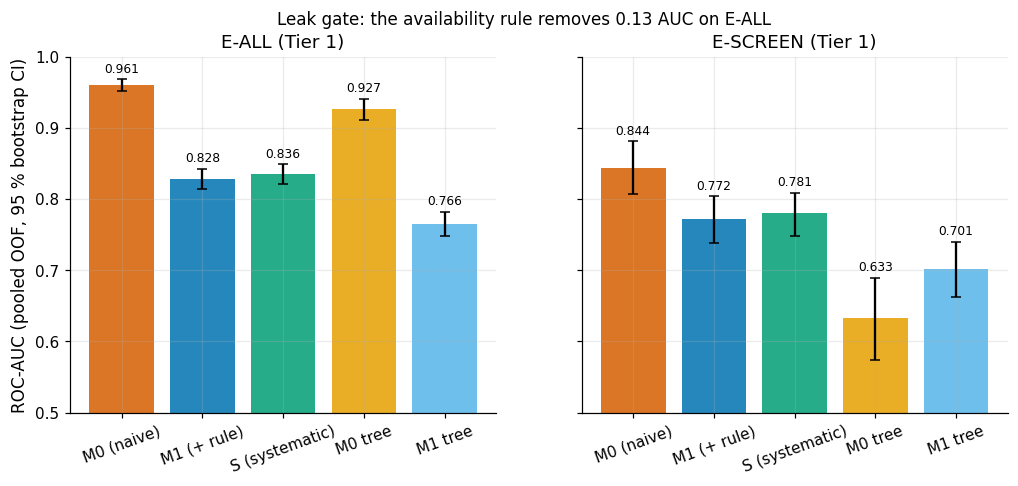

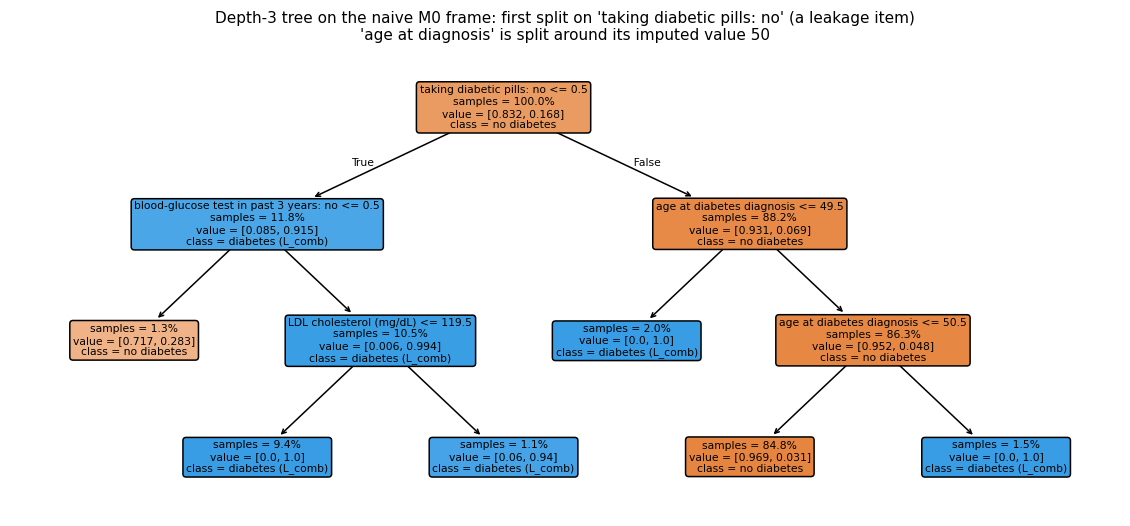

In [8]:
# Leak gate (§7.5): compare M1 with M0 and S with S-B2, and fit depth-3 trees to see where the M0 signal comes
# from.
# Produces the leak-gate figure and the M0 tree plot; the tree verdict (b2t) is computed in code.
from sklearn.tree import plot_tree

gate = {}
# M1 - M0 (negative = leakage removed) in both tiers and both populations.
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        gate[(t, pop)] = cmp_("M1", "M0", t, "roc_auc", pop, label="B2 leak gate")
        print(f"Tier {t} {pop:8s} AUC M1 - M0 = {fmt(gate[(t, pop)])}")
# Leave-one-block-out view of the same block: S minus S without the availability rule.
for pop in ("E-ALL", "E-SCREEN"):
    r = cmp_("S", "S-B2", 1, "roc_auc", pop, label="B2 LOBO")
    print(f"Tier 1 {pop:8s} AUC S - (S-B2) = {fmt(r)}")

# Map an encoded feature name (e.g. 'variable_level') to its source variable by longest-prefix match.
def base_var(name):
    for v in sorted(P._spec_by_var().index, key=len, reverse=True):
        if name == v or name.startswith(v + "_"):
            return v
    return name

# For each tree arm record the root split, its role in the variable spec and the second-level splits.
roots, trees = {}, {}
for arm in ("M0", "M1", "S"):
    cfg = P.ARMS[arm]
    # Depth-3 tree probe fitted on the whole training part (not cross-validated): read for structure, not
    # scored.
    pipe = P.build_pipeline(cfg, 1, model="tree").fit(X[1], P.training_label(raw_tr, cfg), **P.fit_params(cfg, raw_tr))
    names = list(pipe[:-1].get_feature_names_out())
    tree = pipe[-1]
    trees[arm] = (tree, names)
    # tree_.feature[0] is the split feature of the root node; negative feature ids mark leaves.
    root = names[tree.tree_.feature[0]]
    rv = base_var(root)
    # Role of the root variable in the variable spec ('leak' marks inadmissible items).
    role = P._spec_by_var()["role"].get(rv, "derived")
    roots[arm] = dict(root_feature=root, variable=rv, role=role, threshold=float(tree.tree_.threshold[0]),
                      level2=[names[tree.tree_.feature[c]] for c in (tree.tree_.children_left[0], tree.tree_.children_right[0])
                              if tree.tree_.feature[c] >= 0])
show(pd.DataFrame(roots).T.rename_axis("arm").reset_index())
from sklearn.tree import export_text
# Refit the M0 tree to read the median that the imputer used for age at diagnosis.
m0_pipe = P.build_pipeline(P.ARMS["M0"], 1, model="tree").fit(X[1], P.training_label(raw_tr, P.ARMS["M0"]))
# DID040 (age at diagnosis) is asked only of diagnosed people; the tree splits around its imputed constant.
did040_fill = m0_pipe.named_steps["impute"].fill_["DID040"]
did040_miss = float(raw_tr["DID040"].isna().mean())
print(export_text(trees["M0"][0], feature_names=[P.plain_label(c) for c in trees["M0"][1]], show_weights=True))
print(f"DID040 (age at diagnosis) is asked only of diagnosed people: missing for {did040_miss:.0%} of the training part, "
      f"median-imputed to {did040_fill:.0f} in M0")
tree_escr = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "tree")].set_index("arm")["escr_auc"]
print(f"tree E-SCREEN AUC: M0 {tree_escr['M0']:.3f}, M1 {tree_escr['M1']:.3f}, S {tree_escr['S']:.3f}")
S7["tree_m0"] = dict(did040_fill=did040_fill, did040_missing_share=did040_miss, escreen_auc=tree_escr.to_dict())
# B2t: supported if the M0 root is a leak item and the M1 root is not an inadmissible ('N') variable.
b2t = "supported" if roots["M0"]["role"] == "leak" and P._spec_by_var()["admissible"].get(roots["M1"]["variable"], "T1") != "N" else "refuted"
print(f"B2t verdict: {b2t}")
S7["leak_gate"] = {f"T{t}_{pop}": {k: gate[(t, pop)][k] for k in ("est", "lo", "hi", "interval", "mdd")} for (t, pop) in gate}
S7["tree_roots"] = roots

# Figure: AUC bars with bootstrap CI for M0, M1, S (logistic) and the M0/M1 trees; E-ALL left, E-SCREEN right.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
bars = [("M0", "lr", "M0 (naive)"), ("M1", "lr", "M1 (+ rule)"), ("S", "lr", "S (systematic)"), ("M0", "tree", "M0 tree"), ("M1", "tree", "M1 tree")]
colors = [C.OKABE_ITO["vermillion"], C.OKABE_ITO["blue"], C.OKABE_ITO["green"], C.OKABE_ITO["orange"], C.OKABE_ITO["sky"]]
for ax, pop, tag in zip(axes, ("E-ALL", "E-SCREEN"), ("eall", "escr")):
    sub = arm_metrics[arm_metrics["tier"] == 1].set_index(["arm", "model"])
    for i, ((a, m, _), c) in enumerate(zip(bars, colors)):
        v_ = sub.loc[(a, m)]
        ax.bar(i, v_[f"{tag}_auc"], color=c, alpha=0.85)
        ax.errorbar(i, v_[f"{tag}_auc"], yerr=[[v_[f"{tag}_auc"] - v_[f"{tag}_auc_lo"]], [v_[f"{tag}_auc_hi"] - v_[f"{tag}_auc"]]],
                    color="k", capsize=3)
        ax.text(i, v_[f"{tag}_auc_hi"] + 0.01, f"{v_[f'{tag}_auc']:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(len(bars)), [b[2] for b in bars], rotation=20)
    ax.set_ylim(0.5, 1.0)
    ax.set_title(f"{pop} (Tier 1)")
axes[0].set_ylabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
fig.suptitle(f"Leak gate: the availability rule removes {-gate[(1, 'E-ALL')]['est']:.2f} AUC on E-ALL", fontsize=11)
plots.savefig(fig, "S7_leak_gate", caption="ROC-AUC of the naive arm M0, the availability-screened arm M1 and the systematic arm S "
              "(logistic regression) and of depth-3 trees, on E-ALL and E-SCREEN, Tier 1, with 95 % bootstrap CIs. "
              "The drop from M0 to M1 is the leakage removed by the availability rule.")
plt.show()

# Figure: the M0 tree, showing the root split on a treatment item and the splits around the imputed value.
fig, ax = plt.subplots(figsize=(13, 5.5))
tree, names = trees["M0"]
plot_tree(tree, feature_names=[P.plain_label(c) for c in names], class_names=["no diabetes", "diabetes (L_comb)"],
          filled=True, impurity=False, proportion=True, rounded=True, fontsize=7, ax=ax)
ax.set_title(f"Depth-3 tree on the naive M0 frame: first split on '{P.plain_label(roots['M0']['root_feature'])}' "
             f"(a leakage item)\n'age at diagnosis' is split around its imputed value {did040_fill:.0f}", fontsize=10)
plots.savefig(fig, "S7_tree_m0", caption="Decision tree (depth 3, min leaf 50) fitted on the naive M0 feature frame (Tier 1, training part). "
              "The root split uses a treatment item that the availability rule removes; the splits at 49.5 / 50.5 on age at diagnosis "
              "isolate the median imputation of an item that is only asked of diagnosed people.")
plt.show()

**So what.** The availability rule removes the "too-good-to-be-true" signal: E-ALL AUC falls by about 0.13, far
beyond the 0.05 locked for B2/H2a. This **deterioration is the correct outcome** – M0 exploited inadmissible items
(treatment, diagnosis history, glucose testing), i.e. the label leaking back in. The tree's root is a *treatment*
item; its age-at-diagnosis splits sit just below and above the median-imputed constant given to everyone never
asked the question. **Imputation has turned skip-pattern missingness into a code for the label.** The leaked tree is
even *worse* for screening than the M1 tree, and the drop is smaller on E-SCREEN, because these items mark the
already diagnosed.

## 6 Baselines on E-SCREEN
**Why.** A model is only interesting if it beats what a clinician already has: the reduced ADA risk test (Bang et al.
2009) – age 0–3, male +1, told high blood pressure +1, physically inactive +1, BMI 0–3 points. Family history and
gestational diabetes are not asked in 2021–23, so the score is **reduced** and compared by AUC and recall at
specificity 0.80, not by its cut-off. BL-ADAlite-LR refits the same items on `L_comb`; BL0 is the no-information prior.

In [9]:
# Baselines on E-SCREEN (§7.6): no-information prior, reduced ADA risk score, and its items refitted on
# L_comb.
# Adds BL0, BL-ADAlite-LR and BL-ADAlite to OOF/PM; asserts BL0 has AUC 0.5 in every fold; writes the
# baselines CSV.
from sklearn.dummy import DummyClassifier

# ADA-lite items (age, sex, hypertension, inactivity, BMI points) from the training part; missing answers
# score 0.
ada = P.ada_lite_items(cl)
# BL0: DummyClassifier(prior) gives everyone the training prevalence, so its AUC must be exactly 0.5.
OOF[("BL0", 1, "dummy")] = ek.cv_predict(lambda: DummyClassifier(strategy="prior"), X[1], y, folds)
PM[("BL0", 1, "dummy")] = ek.mean_oof(OOF[("BL0", 1, "dummy")], n)
bl0_fold = ek.fold_metrics(OOF[("BL0", 1, "dummy")], y)["roc_auc"]
# Guard: a no-information model must score 0.5 in every fold, otherwise the evaluation hides optimism.
assert np.allclose(bl0_fold, 0.5), "BL0 must have AUC 0.500 in every fold"
# Refit the same ADA items as a logistic regression (frozen C0) on L_comb, using the stored folds.
OOF[("BL-ADAlite-LR", 1, "lr")] = ek.cv_predict(lambda: P.ada_lr_pipeline(C0), ada, y, folds)
PM[("BL-ADAlite-LR", 1, "lr")] = ek.mean_oof(OOF[("BL-ADAlite-LR", 1, "lr")], n)
# The integer ADA points serve directly as a score, with no fitting (model key 'points').
ada_score = ada["ada_score"].to_numpy(float)
PM[("BL-ADAlite", 1, "points")] = ada_score
# Number of missing answers per ADA item (scored 0 in the points).
miss = ada[["ada_htn_missing", "ada_inactive_missing", "ada_bmi_missing"]].sum().to_dict()
print(f"ADA-lite item availability: missing answers scored 0 -> {miss}")
print(f"ADA-lite score distribution in E-SCREEN: {pd.Series(ada_score[esc]).value_counts().sort_index().to_dict()}")

# Baselines and main arms on E-SCREEN: AUC with bootstrap CI, PR-AUC, recall at 80 % specificity.
base_rows = []
for name, key in [("BL0 (prior)", ("BL0", 1, "dummy")), ("BL-ADAlite (points)", ("BL-ADAlite", 1, "points")),
                  ("BL-ADAlite-LR", ("BL-ADAlite-LR", 1, "lr")), ("M1", ("M1", 1, "lr")), ("S", ("S", 1, "lr")),
                  ("T1-minus-care", ("T1-minus-care", 1, "lr")), ("S Tier 2", ("S", 2, "lr"))]:
    p = PM[key]
    ms = ek.metric_suite(y_esc[esc], p[esc])
    a_, lo_, hi_ = auc_ci(p, "E-SCREEN", seed_tag=name)
    base_rows.append(dict(model=name, escr_auc=a_, lo=lo_, hi=hi_, escr_pr_auc=ms["pr_auc"],
                          escr_recall_spec80=ms["recall_at_spec"], eall_auc=roc_auc_score(y, p)))
baselines = pd.DataFrame(base_rows)
baselines.to_csv(OUT / "baselines_escreen.csv", index=False)
show(baselines, 3)
print(f"BL0 per-fold AUC (E-ALL): all exactly {bl0_fold.iloc[0]:.3f}; E-SCREEN prevalence {y_esc[esc].mean():.3f} = BL0 PR-AUC level")
# Paired E-SCREEN comparisons: S vs ADA points (H2c-iii), S vs refitted ADA-LR, no-care arm vs ADA points.
h2c3 = cmp_("S", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="H2c(iii)")
s_vs_adalr = cmp_("S", "BL-ADAlite-LR", 1, "roc_auc", "E-SCREEN", pb=PM[("BL-ADAlite-LR", 1, "lr")], label="S vs ADA-LR")
care_vs_ada = cmp_("T1-minus-care", "BL-ADAlite", 1, "roc_auc", "E-SCREEN", pb=ada_score, label="T1-minus-care vs ADA")
print(f"E-SCREEN AUC S - ADA-lite points = {fmt(h2c3)}")
print(f"E-SCREEN AUC S - ADA-lite-LR     = {fmt(s_vs_adalr)}")
print(f"E-SCREEN AUC T1-minus-care - ADA-lite points = {fmt(care_vs_ada)}")
# Does refitting the ADA items on L_comb help? Compared with the plain points in both populations.
adalr_vs_pts = {pop: cmp_("BL-ADAlite-LR", "BL-ADAlite", 1, "roc_auc", pop, pa=PM[("BL-ADAlite-LR", 1, "lr")], pb=ada_score,
                          label="ADA-LR vs ADA points") for pop in ("E-ALL", "E-SCREEN")}
for pop, r in adalr_vs_pts.items():
    print(f"{pop:8s} AUC ADA-lite-LR - ADA-lite points = {fmt(r)}")
S7["ada_lr_minus_points"] = {pop: {k: r[k] for k in ("est", "lo", "hi")} for pop, r in adalr_vs_pts.items()}
S7["baselines"] = baselines.set_index("model").to_dict("index")
S7["ada_missing_answers"] = miss

ADA-lite item availability: missing answers scored 0 -> {'ada_htn_missing': 4, 'ada_inactive_missing': 39, 'ada_bmi_missing': 62}
ADA-lite score distribution in E-SCREEN: {0.0: 171, 1.0: 353, 2.0: 513, 3.0: 675, 4.0: 695, 5.0: 666, 6.0: 512, 7.0: 271, 8.0: 69, 9.0: 9}


model,escr_auc,lo,hi,escr_pr_auc,escr_recall_spec80,eall_auc
BL0 (prior),0.497,0.443,0.546,0.031,0.134,0.503
BL-ADAlite (points),0.726,0.681,0.764,0.077,0.244,0.761
BL-ADAlite-LR,0.708,0.665,0.752,0.079,0.449,0.768
M1,0.772,0.738,0.804,0.093,0.535,0.828
S,0.781,0.747,0.812,0.091,0.520,0.836
T1-minus-care,0.800,0.769,0.831,0.108,0.614,0.820
S Tier 2,0.790,0.758,0.823,0.104,0.535,0.850


BL0 per-fold AUC (E-ALL): all exactly 0.500; E-SCREEN prevalence 0.032 = BL0 PR-AUC level


E-SCREEN AUC S - ADA-lite points = +0.055 [+0.026, +0.083] (bootstrap, MDD 0.041)
E-SCREEN AUC S - ADA-lite-LR     = +0.072 [+0.041, +0.103] (bootstrap, MDD 0.044)
E-SCREEN AUC T1-minus-care - ADA-lite points = +0.074 [+0.043, +0.106] (bootstrap, MDD 0.046)


E-ALL    AUC ADA-lite-LR - ADA-lite points = +0.006 [-0.001, +0.014] (bootstrap, MDD 0.010)
E-SCREEN AUC ADA-lite-LR - ADA-lite points = -0.018 [-0.032, -0.002] (bootstrap, MDD 0.021)


**So what.** BL0 sits at AUC 0.500 in every fold (asserted) and at the prevalence for PR-AUC, so the evaluation has
no built-in optimism. The reduced ADA score reaches an E-SCREEN AUC of about 0.73 with integer points and no
fitting; S is better by about 0.05 with a CI excluding 0 (H2c-iii). The one-shot hold-out does not replicate this
margin (§9.11), and ADA-lite lacks two items, so the margin likely overstates what a complete ADA test would concede.
Refitting the ADA items on `L_comb` (BL-ADAlite-LR) leaves E-ALL unchanged but *lowers* E-SCREEN AUC by about 0.02:
weights learned from a label dominated by known diabetics do not transfer to screening.

## 7 Cumulative path M0 → S
**Why.** The cumulative path shows how the AUC moves as blocks are added in the pre-specified order. Increments depend
on the order, so they are descriptive; verdicts come from leave-one-block-out (§7.8).

pop,step,est,lo,hi,interval,mdd
E-ALL,M0 -> M1,-0.1308,-0.1479,-0.1138,corrected_t,0.0241
E-ALL,M1 -> cum+B1,0.0009,-0.0021,0.0040,corrected_t,0.0043
E-ALL,cum+B1 -> cum+B3,0.0023,-0.0027,0.0074,corrected_t,0.0071
E-ALL,cum+B3 -> cum+B4,0.0007,-0.0011,0.0025,corrected_t,0.0025
E-ALL,cum+B4 -> cum+B5,0.0060,0.0011,0.0109,bootstrap,0.0074
E-ALL,cum+B5 -> cum+B6a,0.0006,-0.0011,0.0023,corrected_t,0.0025
E-ALL,cum+B6a -> S,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-SCREEN,M0 -> M1,-0.0718,-0.1133,-0.0310,bootstrap,0.0587
E-SCREEN,M1 -> cum+B1,0.0029,-0.0015,0.0071,bootstrap,0.0061
E-SCREEN,cum+B1 -> cum+B3,0.0041,-0.0036,0.0117,bootstrap,0.0108


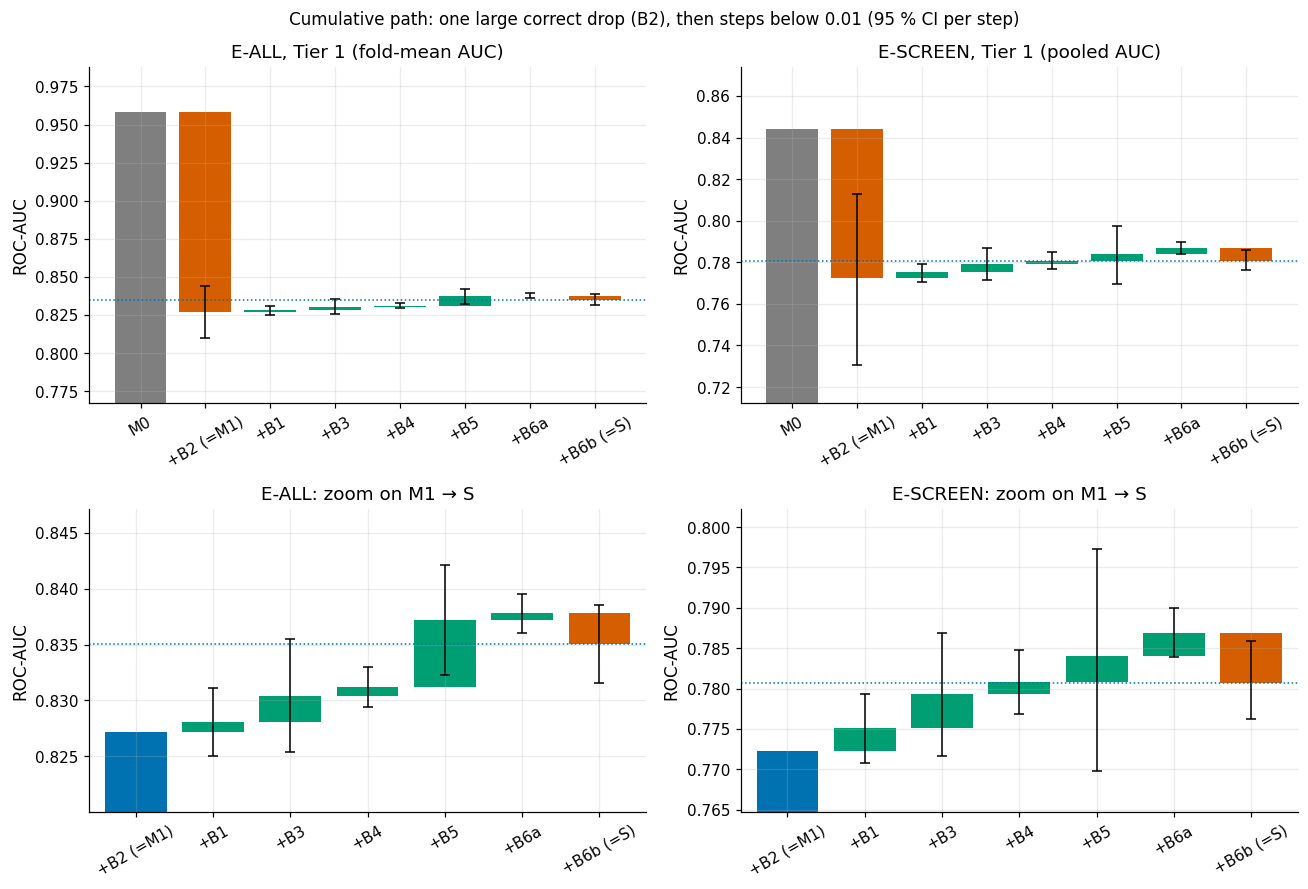

In [10]:
# Cumulative path M0 -> S (§7.7): paired AUC difference between consecutive arms in the pre-specified block
# order.
# Writes cumulative_path.csv and the waterfall figure; increments are descriptive because they depend on the
# order.
cum_rows = []
# P.CUMULATIVE lists the arms in the pre-specified order.
path = list(P.CUMULATIVE)
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for prev, cur in zip(path[:-1], path[1:]):
            r = cmp_(cur, prev, t, "roc_auc", pop, label="cumulative")
            r["step"] = f"{prev} -> {cur}"
            cum_rows.append(r)
cum = pd.DataFrame(cum_rows)
cum.to_csv(OUT / "cumulative_path.csv", index=False)
show(cum[cum["tier"] == 1][["pop", "step", "est", "lo", "hi", "interval", "mdd"]], 4)

# Waterfall: top row full scale, bottom row zoomed on the steps after the leak gate.
fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), gridspec_kw={"height_ratios": [1, 0.9]})
labels_ = ["M0", "+B2 (=M1)", "+B1", "+B3", "+B4", "+B5", "+B6a", "+B6b (=S)"]
sub = arm_metrics[(arm_metrics["tier"] == 1) & (arm_metrics["model"] == "lr")].set_index("arm")
# Start level: E-ALL uses the fold-mean AUC, E-SCREEN the pooled AUC (same estimand as the step differences).
for col, (pop, lev_col) in enumerate((("E-ALL", "eall_auc_foldmean"), ("E-SCREEN", "escr_auc"))):
    c = cum[(cum["tier"] == 1) & (cum["pop"] == pop)].reset_index(drop=True)
    levels = [sub.loc[path[0], lev_col]]
    for _, r in c.iterrows():
        levels.append(levels[-1] + r["est"])     # E-ALL: fold-mean steps; E-SCREEN: pooled steps
    for row, start in ((0, 0), (1, 1)):          # row 1 = zoom on M1 -> S
        ax = axes[row, col]
        ax.bar(start, levels[start], color=C.OKABE_ITO["grey"] if start == 0 else C.OKABE_ITO["blue"])
        for i in range(start, len(c)):
            r, d = c.loc[i], c.loc[i, "est"]
            ax.bar(i + 1, d, bottom=levels[i], color=C.OKABE_ITO["vermillion"] if d < 0 else C.OKABE_ITO["green"])
            ax.errorbar(i + 1, levels[i] + d, yerr=[[max(d - r["lo"], 0)], [max(r["hi"] - d, 0)]], color="k", capsize=3, lw=1)
        ax.axhline(levels[-1], color=C.OKABE_ITO["blue"], ls=":", lw=1)
        ax.set_xticks(range(start, len(labels_)), labels_[start:], rotation=30)
        # Vertical range of the zoom panel: bar tops and CI ends of all steps shown.
        span = [levels[k] + dlt for k in range(start, len(c)) for dlt in (0, c.loc[k, "lo"], c.loc[k, "hi"])]
        if row == 0:
            ax.set_ylim(min(levels) - 0.06, max(levels) + 0.03)
            ax.set_title(f"{pop}, Tier 1 ({'fold-mean' if pop == 'E-ALL' else 'pooled'} AUC)")
        else:
            ax.set_ylim(min(span) - 0.005, max(span) + 0.005)
            ax.set_xlim(start - 0.6, len(labels_) - 0.4)
            ax.set_title(f"{pop}: zoom on M1 → S")
        ax.set_ylabel("ROC-AUC")
fig.suptitle("Cumulative path: one large correct drop (B2), then steps below 0.01 (95 % CI per step)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_waterfall", caption="Waterfall of the ROC-AUC along the cumulative path M0 -> +B2 -> +B1 -> +B3 -> +B4 -> +B5 -> +B6a -> +B6b (= S), "
              "Tier 1. E-ALL: fold-mean AUC and fold-mean paired differences with the conservative 95 % CI (wider of corrected t and "
              "bootstrap); E-SCREEN: pooled-OOF AUC and bootstrap CI. Bottom row: zoom on the steps after the leak gate. "
              "Red = decrease, green = increase; dotted line = S.")
plt.show()

**So what.** After the leak gate every block moves E-ALL AUC by less than the 0.01 SESOI, each step about the size of
its own MDD. The systematic pipeline does not "buy" discrimination; its value lies in fidelity, stability and
calibration, which is what the block hypotheses predicted and what §7.8–§7.11 test.

## 8 Leave-one-block-out
**Why.** The contribution of a block given every other step is S − (S without the block). These are the primary
block comparisons of the locked hypotheses, evaluated on both populations and both tiers, plus the extra arms
S-linear (splines only), S+WHtR (P14) and T1-minus-care.

pop,block,est,lo,hi,interval,mdd
E-ALL,B1,0.0019,-0.0011,0.0049,corrected_t,0.0042
E-ALL,B2,-0.1217,-0.1381,-0.1053,corrected_t,0.0232
E-ALL,B3,0.0019,-0.0018,0.0055,corrected_t,0.0051
E-ALL,B4,0.0002,-0.0019,0.0024,corrected_t,0.0030
E-ALL,B5,0.0065,0.0024,0.0107,bootstrap,0.0063
E-ALL,B6a,0.0006,-0.0017,0.0028,corrected_t,0.0032
E-ALL,B6b,-0.0027,-0.0062,0.0008,corrected_t,0.0050
E-ALL,splines,0.0038,0.0005,0.0074,bootstrap,0.0050
E-ALL,P14 WHtR,-0.0009,-0.0028,0.0009,corrected_t,0.0026
E-ALL,care items,0.0159,0.0094,0.0220,bootstrap,0.0095


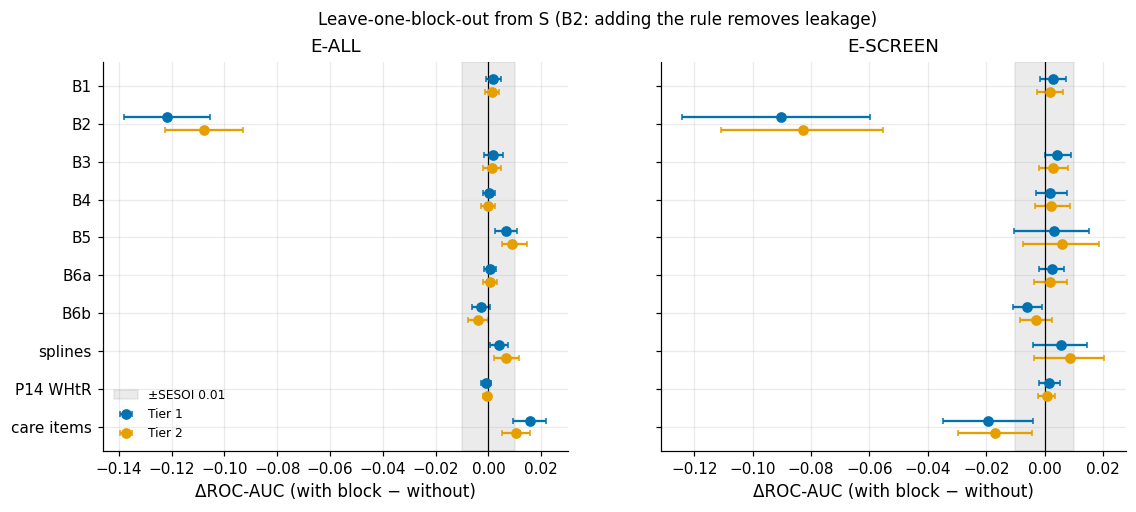

In [11]:
# Leave-one-block-out (§7.8): AUC, PR-AUC and Brier of S minus S without each block, per population and tier.
# Writes lobo.csv and the forest figure; the primary rows feed the verdicts in §7.12.
# Pairs are (with block, without block), so every difference reads 'with minus without'.
lobo_pairs = [("S", f"S-{b}", b) for b in P.BLOCKS] + [("S", "S-linear", "splines"), ("S+WHtR", "S", "P14 WHtR"),
                                                       ("S", "T1-minus-care", "care items")]
lobo_rows = []
for t in (1, 2):
    for pop in ("E-ALL", "E-SCREEN"):
        for a, b, lab in lobo_pairs:
            for metric in ("roc_auc", "pr_auc", "brier"):
                r = cmp_(a, b, t, metric, pop, label=f"LOBO {lab}")
                r["block"] = lab
                lobo_rows.append(r)
lobo = pd.DataFrame(lobo_rows)
lobo.to_csv(OUT / "lobo.csv", index=False)
# Tier-1 AUC rows for the printed table; the CSV holds every metric.
v_ = lobo[(lobo["tier"] == 1) & (lobo["metric"] == "roc_auc")]
show(v_[["pop", "block", "est", "lo", "hi", "interval", "mdd"]], 4)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
order = [lab for _, _, lab in lobo_pairs]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    for t, off, col in ((1, -0.17, C.OKABE_ITO["blue"]), (2, 0.17, C.OKABE_ITO["orange"])):
        s = lobo[(lobo["tier"] == t) & (lobo["metric"] == "roc_auc") & (lobo["pop"] == pop)].set_index("block").loc[order]
        ax.errorbar(s["est"], np.arange(len(order)) + off, xerr=[s["est"] - s["lo"], s["hi"] - s["est"]], fmt="o",
                    color=col, capsize=2, label=f"Tier {t}")
    # Grey band = smallest effect size of interest (SESOI) for AUC; effects inside it are practically zero.
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=C.OKABE_ITO["grey"], alpha=0.15, label="±SESOI 0.01")
    ax.axvline(0, color="k", lw=0.8)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("ΔROC-AUC (with block − without)")
    ax.set_title(pop)
axes[0].invert_yaxis()
axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Leave-one-block-out from S (B2: adding the rule removes leakage)", fontsize=11)
plots.savefig(fig, "S7_lobo", caption="Leave-one-block-out ΔROC-AUC = AUC(arm with the block) − AUC(arm without it) with conservative 95 % CIs, Tier 1 (blue) and "
              "Tier 2 (orange), E-ALL and E-SCREEN; grey band = ±SESOI 0.01. Every row is 'with − without': B2 is negative because adding the "
              "rule removes leakage; 'care items' = S − T1-minus-care (S keeps BPQ020/BPQ080); 'P14 WHtR' = S+WHtR − S.")
plt.show()

**So what.** Apart from B2 (negative because adding the rule removes leakage), block effects on discrimination are
small; their intervals decide between "equivalent" (inside the grey band) and "inconclusive" (crossing it). The
striking line is **care items** ("told high blood pressure / high cholesterol"): keeping them helps on E-ALL but
*hurts* on E-SCREEN. They help to recognise people the health system already knows, which is not the screening task.

## 9 E-ALL vs E-SCREEN
**Why.** 84 % of the `L_comb` positives already know their diagnosis, so an AUC on E-ALL largely measures how well a
model recognises *known* patients, who carry traces of care. The screening question is E-SCREEN. The gap between the
two is the pre-registered H2c(i).

S (Tier 1): AUC E-ALL 0.836 - E-SCREEN 0.781 = +0.055 [+0.028, +0.086] (bootstrap, MDD 0.040)
same 3,807 negatives in both populations; positives: E-ALL 777 (all L_comb), E-SCREEN 127 (undiagnosed only)
gap lower bound 0.028 vs pre-registered magnitude 0.03


arm,eall,eall_lo,eall_hi,escr,escr_lo,escr_hi,gap
M0,0.961,0.952,0.968,0.844,0.809,0.879,0.117
M1,0.828,0.814,0.841,0.772,0.739,0.804,0.056
S,0.836,0.822,0.848,0.781,0.746,0.812,0.055
S-linear,0.832,0.818,0.845,0.775,0.741,0.807,0.057
T1-minus-care,0.820,0.808,0.835,0.800,0.766,0.831,0.020
S+WHtR,0.835,0.821,0.847,0.782,0.749,0.814,0.053
S (T2),0.850,0.836,0.863,0.790,0.756,0.821,0.060
BL-ADAlite-LR,0.768,0.750,0.786,0.708,0.666,0.750,0.060
BL-ADAlite,0.761,0.745,0.778,0.726,0.687,0.769,0.035


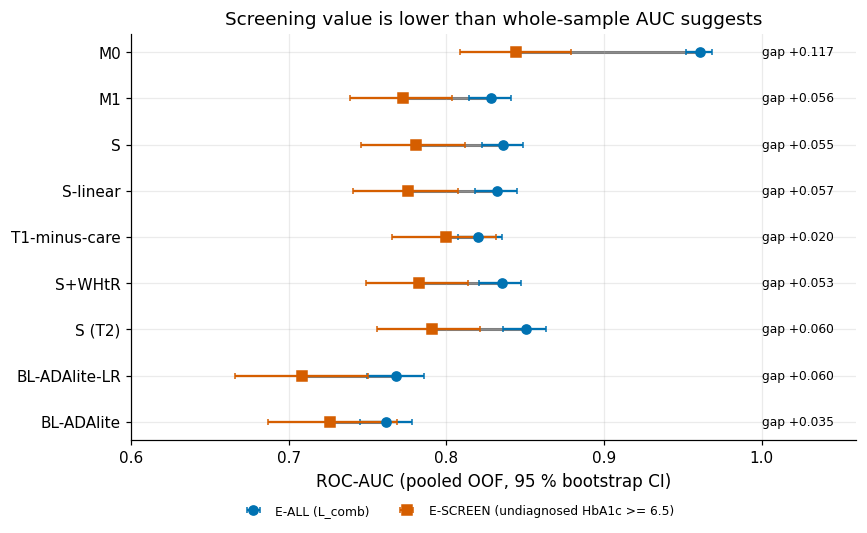

In [12]:
# E-ALL vs E-SCREEN gap (§7.9): bootstrap of AUC(E-ALL) - AUC(E-SCREEN) for S, and a gap table for the main
# arms.
# Asserts that both populations share the same negatives; writes eall_vs_escreen.csv and a dumbbell figure.
rng = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "H2c-i"))
# Resampling units: rows within each label stratum, so each bootstrap sample keeps the stratum mix.
groups = [np.flatnonzero(strat == s) for s in np.unique(strat)]
pS = PM[("S", 1, "lr")]
gaps = []
# Both AUCs are computed on the same resampled rows, so the gap is a paired quantity.
for _ in range(C.N_BOOT):
    idx = np.concatenate([rng.choice(g, len(g)) for g in groups])
    # E-SCREEN members among the resampled indices.
    e = idx[esc[idx]]
    gaps.append(roc_auc_score(y[idx], pS[idx]) - roc_auc_score(y_esc[e], pS[e]))
gaps = np.array(gaps)
gap_obs = roc_auc_score(y, pS) - roc_auc_score(y_esc[esc], pS[esc])
gap_lo, gap_hi = np.percentile(gaps, [2.5, 97.5])
# SE = bootstrap SD; MDD from normal quantiles (80 % power, two-sided 5 %).
h2c1 = dict(a="S", b="S", tier=1, metric="roc_auc", pop="E-ALL minus E-SCREEN", est=gap_obs, lo=gap_lo, hi=gap_hi,
            se=gaps.std(ddof=1), interval="bootstrap", mdd=(stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) * gaps.std(ddof=1),
            label="H2c(i)")
COMP.append(h2c1)
print(f"S (Tier 1): AUC E-ALL {roc_auc_score(y, pS):.3f} - E-SCREEN {roc_auc_score(y_esc[esc], pS[esc]):.3f} = {fmt(h2c1)}")
# Spectrum-bias design: the populations differ only in their positives (known diabetics vs undiagnosed).
neg_eall, neg_escr = set(np.flatnonzero(y == 0)), set(np.flatnonzero(esc & (y_esc == 0)))
assert neg_eall == neg_escr, "E-ALL and E-SCREEN must share the same negatives"
print(f"same {len(neg_eall):,} negatives in both populations; positives: E-ALL {int(y.sum())} (all L_comb), "
      f"E-SCREEN {int(y_esc[esc].sum())} (undiagnosed only)")
# H2c(i) was pre-registered with magnitude 0.03; the lower CI bound is compared with it.
print(f"gap lower bound {h2c1['lo']:.3f} vs pre-registered magnitude 0.03")

# Arms for the gap table; the ADA points are used in their raw 'points' form.
pairs = [("M0", 1, "lr"), ("M1", 1, "lr"), ("S", 1, "lr"), ("S-linear", 1, "lr"), ("T1-minus-care", 1, "lr"),
         ("S+WHtR", 1, "lr"), ("S", 2, "lr"), ("BL-ADAlite-LR", 1, "lr"), ("BL-ADAlite", 1, "points")]
dumb = []
for k in pairs:
    a1, l1, h1 = auc_ci(PM[k], "E-ALL", seed_tag=f"d{k}")
    a2, l2, h2 = auc_ci(PM[k], "E-SCREEN", seed_tag=f"d{k}")
    dumb.append(dict(arm=f"{k[0]}" + (" (T2)" if k[1] == 2 else ""), eall=a1, eall_lo=l1, eall_hi=h1, escr=a2, escr_lo=l2, escr_hi=h2))
dumb = pd.DataFrame(dumb)
dumb["gap"] = dumb["eall"] - dumb["escr"]
dumb.to_csv(OUT / "eall_vs_escreen.csv", index=False)
show(dumb, 3)

# Dumbbell plot: each line joins an arm's E-SCREEN (square) and E-ALL (circle) AUC.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for i, r in dumb.iterrows():
    ax.plot([r["escr"], r["eall"]], [i, i], color=C.OKABE_ITO["grey"], lw=2, zorder=1)
    ax.errorbar(r["eall"], i, xerr=[[r["eall"] - r["eall_lo"]], [r["eall_hi"] - r["eall"]]], fmt="o", color=C.OKABE_ITO["blue"],
                capsize=2, label="E-ALL (L_comb)" if i == 0 else None, zorder=2)
    ax.errorbar(r["escr"], i, xerr=[[r["escr"] - r["escr_lo"]], [r["escr_hi"] - r["escr"]]], fmt="s", color=C.OKABE_ITO["vermillion"],
                capsize=2, label="E-SCREEN (undiagnosed HbA1c >= 6.5)" if i == 0 else None, zorder=2)
    ax.text(1.0, i, f"gap {r['gap']:+.3f}", va="center", fontsize=8)
ax.set_yticks(range(len(dumb)), dumb["arm"])
ax.invert_yaxis()
ax.set_xlim(0.6, 1.06)
ax.set_xlabel("ROC-AUC (pooled OOF, 95 % bootstrap CI)")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.13), ncol=2, fontsize=8, frameon=False)
ax.set_title("Screening value is lower than whole-sample AUC suggests")
plots.savefig(fig, "S7_eall_vs_escreen", caption="ROC-AUC on E-ALL (blue, L_comb, 84 % already diagnosed) and E-SCREEN (red, people not told they have "
              "diabetes, positive = HbA1c >= 6.5 %) for the main arms and baselines, Tier 1 unless marked, with 95 % bootstrap CIs.")
plt.show()

**So what.** The two populations share exactly the same negatives (asserted); only the positives differ, so the gap
is pure **spectrum bias** (Ransohoff & Feinstein 1978): known diabetics, with treatment, care contacts and higher
HbA1c, are easier to rank than the undiagnosed. For S the gap is about 0.055 (H2c-i supported); its lower bound
(about 0.028) sits just below the pre-registered 0.03. The smaller gaps of T1-minus-care and ADA-lite are the mirror
image: the less a model relies on care traces, the less it loses. A whole-sample AUC overstates screening value –
the label composition, not the model, sets the headline number.

## 10 Precision–recall and calibration
**Why.** AUC ignores prevalence and calibration. E-SCREEN has a prevalence of about 3 %, so precision binds in
screening, and a model trained on `L_comb` (17 %) is miscalibrated there by design; class weights (B6a) inflate
probabilities further.

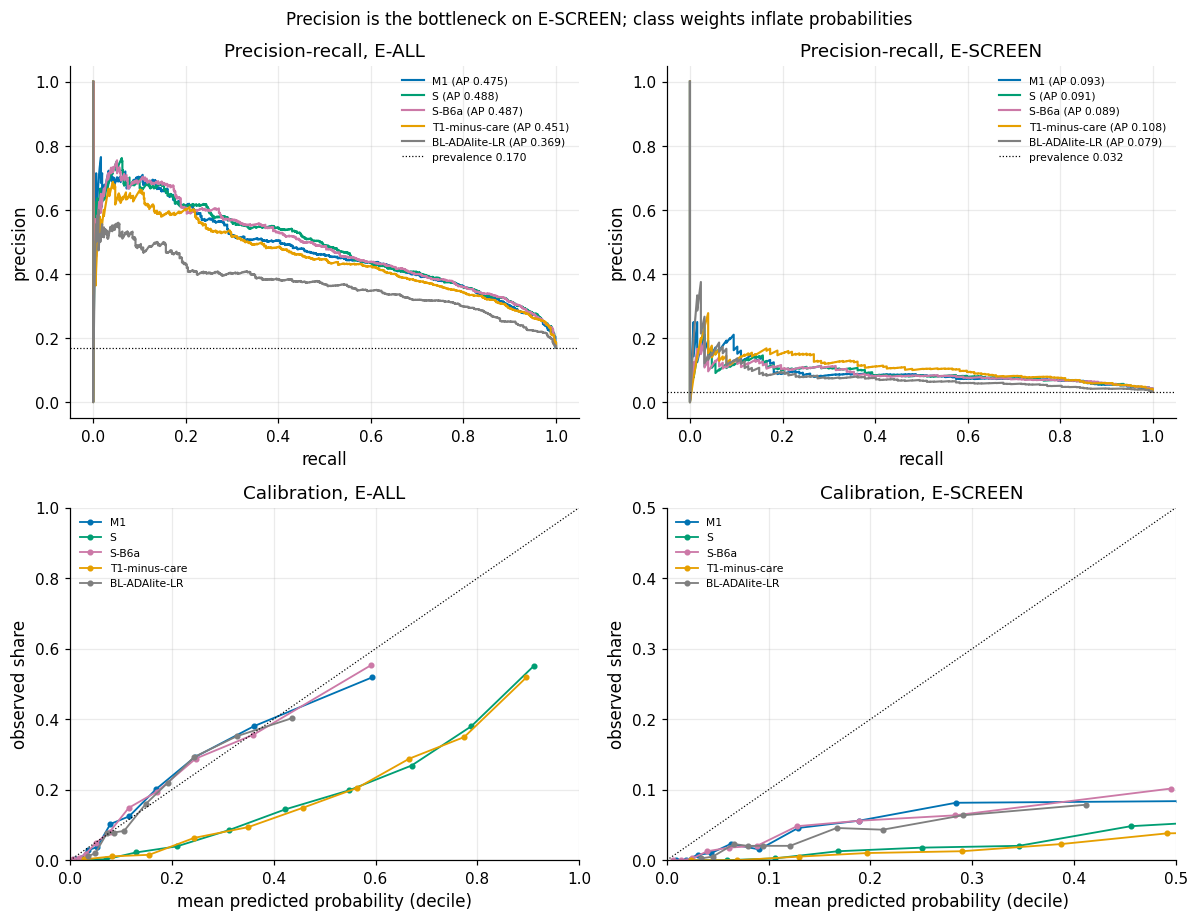

arm,pop,cal_slope,cal_citl,brier,mean_p,prevalence
M1,E-ALL,0.961,0.010,0.112,0.168,0.170
S,E-ALL,0.867,-1.818,0.185,0.409,0.170
S-B6a,E-ALL,0.979,0.027,0.110,0.167,0.170
T1-minus-care,E-ALL,0.873,-1.807,0.195,0.422,0.170
BL-ADAlite-LR,E-ALL,1.124,-0.001,0.123,0.170,0.170
M1,E-SCREEN,0.685,-1.814,0.056,0.136,0.032
S,E-SCREEN,0.613,-3.671,0.196,0.357,0.032
S-B6a,E-SCREEN,0.688,-1.783,0.055,0.133,0.032
T1-minus-care,E-SCREEN,0.723,-3.684,0.205,0.376,0.032
BL-ADAlite-LR,E-SCREEN,0.831,-1.799,0.054,0.152,0.032


In [13]:
# Precision-recall and calibration (§7.10) of selected Tier-1 arms on E-ALL and E-SCREEN.
# Writes calibration.csv and the PR/calibration figure; no assertions.
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve

# Arms shown: M1, S, S without class weights (S-B6a), the no-care variant and the refitted ADA baseline.
curve_keys = [("M1", 1, "lr", C.OKABE_ITO["blue"]), ("S", 1, "lr", C.OKABE_ITO["green"]),
              ("S-B6a", 1, "lr", C.OKABE_ITO["purple"]), ("T1-minus-care", 1, "lr", C.OKABE_ITO["orange"]),
              ("BL-ADAlite-LR", 1, "lr", C.OKABE_ITO["grey"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
cal_rows = []
for col, pop in enumerate(("E-ALL", "E-SCREEN")):
    yy, m = pop_of(pop)
    for a, t, mdl, colr in curve_keys:
        p = PM[(a, t, mdl)][m]
        prec, rec, _ = precision_recall_curve(yy[m], p)
        axes[0, col].plot(rec, prec, color=colr, lw=1.4, label=f"{a} (AP {average_precision_score(yy[m], p):.3f})")
        # Decile calibration: quantile bins hold equally many cases per point.
        fr, mp = calibration_curve(yy[m], p, n_bins=10, strategy="quantile")
        axes[1, col].plot(mp, fr, "o-", color=colr, ms=3, lw=1.2, label=a)
        # metric_suite supplies the calibration slope and calibration-in-the-large (citl) of each arm and
        # population.
        ms_ = ek.metric_suite(yy[m], p)
        cal_rows.append(dict(arm=a, pop=pop, cal_slope=ms_["cal_slope"], cal_citl=ms_["cal_citl"], brier=ms_["brier"],
                             mean_p=float(p.mean()), prevalence=float(yy[m].mean())))
    axes[0, col].axhline(yy[m].mean(), color="k", ls=":", lw=0.8, label=f"prevalence {yy[m].mean():.3f}")
    axes[0, col].set(xlabel="recall", ylabel="precision", title=f"Precision-recall, {pop}")
    axes[0, col].legend(fontsize=7)
    # E-SCREEN probabilities are small, so its calibration axes stop at 0.5.
    lim = 1.0 if pop == "E-ALL" else 0.5
    axes[1, col].plot([0, lim], [0, lim], color="k", lw=0.8, ls=":")
    axes[1, col].set(xlabel="mean predicted probability (decile)", ylabel="observed share", title=f"Calibration, {pop}",
                     xlim=(0, lim), ylim=(0, lim))
    axes[1, col].legend(fontsize=7)
fig.suptitle("Precision is the bottleneck on E-SCREEN; class weights inflate probabilities", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S7_pr_calibration", caption="Top: precision-recall curves (average precision in the legend; dotted line = prevalence). Bottom: "
              "calibration by deciles of the predicted probability. Left E-ALL, right E-SCREEN; Tier 1 pooled OOF predictions. S uses "
              "balanced class weights; S-B6a is S without them.")
plt.show()
cal = pd.DataFrame(cal_rows)
cal.to_csv(OUT / "calibration.csv", index=False)
show(cal, 3)

**So what.** On E-SCREEN average precision is only about 0.1 against a prevalence of about 0.03: a screening tool
built on these items would mostly flag people without diabetes. The calibration panels show the price of class
weights – S predicts far above the observed prevalence, while S−B6a (no class weights) is close to the diagonal on
E-ALL. On E-SCREEN every model over-predicts, having been trained where 17 % are positive.

## 11 Coefficient stability
**Why.** Discrimination can hide unstable explanations: collinear anthropometrics share the BMI signal differently in
every resample. A nonparametric bootstrap of the whole pipeline (B = 500 in FINAL, 30 in FAST) measures this. BMI is
compared per SD across the arms in which it enters linearly (S is represented by S-linear, as locked); B3-b compares
S-linear−B3 with S-linear, H2b(c) compares M1 with S-linear. The *ratio* of two bootstrap SDs is reported as a
descriptive number: the interval around it comes from re-drawing the stored bootstrap replicates (Monte Carlo
error), not from re-sampling patients, so it is not a sampling interval and cannot decide a hypothesis.

arm,bmi_coef_per_sd,bmi_sd_per_sd,bmi_q_low,bmi_q_high,bmi_sign_flip,max_flip_anthro,anthro_in_model,n_coef,n_valid,share_flip_gt_10pct
M1,0.585,0.301,-0.164,1.075,0.120,0.822,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.391
cum+B1,0.240,0.354,-0.160,1.186,0.124,0.348,"BMXBMI,BMXWT,BMXHT,BMXWAIST",46,500,0.457
cum+B3,0.407,0.124,0.199,0.694,0.000,0.134,"BMXBMI,BMXHT,BMXWAIST",29,500,0.276
S-linear-B3,0.338,0.207,0.041,0.917,0.010,0.092,"BMXBMI,BMXWT,BMXHT,BMXWAIST",50,337,0.500
S-linear,0.699,0.152,0.433,1.035,0.000,0.484,"BMXBMI,BMXHT,BMXWAIST",34,500,0.353


SD ratio BMI S-linear-B3 / S-linear: 1.36, Monte Carlo interval [1.23, 1.50] (B = 500) -> descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9
SD ratio BMI M1 / S-linear: 1.98, Monte Carlo interval [1.80, 2.17] (B = 500) -> descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9
SD ratio BMI cum+B1 / cum+B3: 2.87, Monte Carlo interval [2.62, 3.12] (B = 500) -> descriptive only (no verdict)


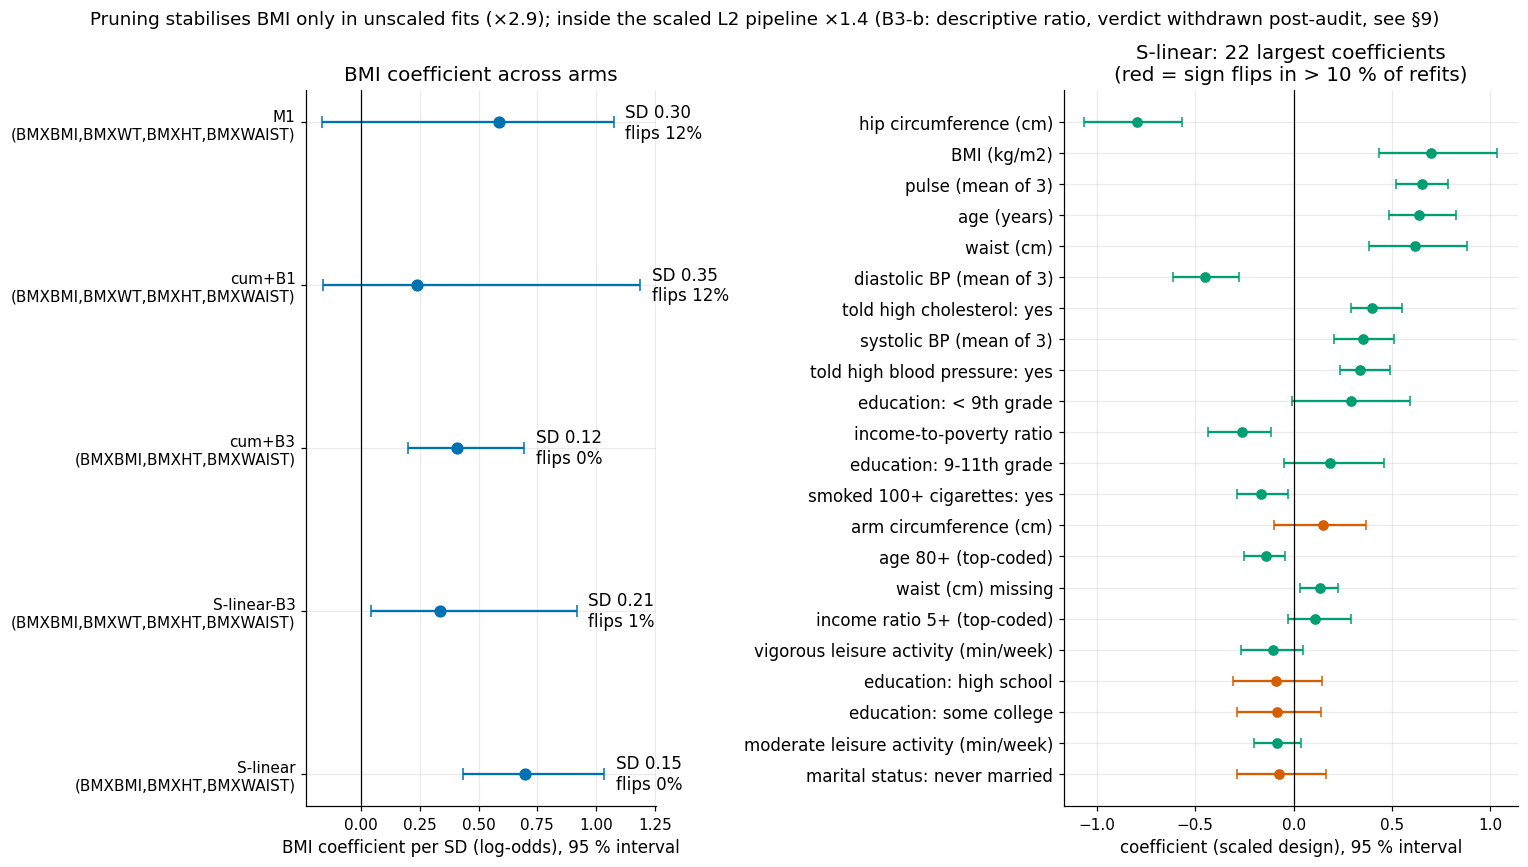

In [14]:
# Coefficient stability (§7.11): bootstrap the whole pipeline for five arms and compare the spread of the BMI
# coefficient.
# Writes coef_stability.csv and the forest figure; B_COEF replicates (fewer in FAST mode).
# Arms in which BMI enters linearly (S is represented by S-linear, as locked).
coef_arms = ["M1", "cum+B1", "cum+B3", "S-linear-B3", "S-linear"]
CB, coef_rows = {}, []
for arm in coef_arms:
    cfg = P.ARMS[arm]
    ylab_ = P.training_label(raw_tr, cfg)
    # Binding cfg=cfg makes the factory build a fresh pipeline of the current arm for each bootstrap
    # replicate.
    mk = (lambda cfg=cfg: P.build_pipeline(cfg, 1, C_=C0))
    # Silence solver warnings inside the replicate fits.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        cb = ek.coef_bootstrap(mk, X[1], ylab_, n_boot=B_COEF, seed=ek.derive_seed(C.SEED_MASTER, "S7", "coef", arm),
                               fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        # BMI standard deviation in the prepared design: coefficient x SD puts all arms on a per-SD scale.
        dsg = mk()[:-1].fit_transform(X[1])
    sd_bmi = float(dsg["BMXBMI"].std(ddof=0))
    CB[arm] = (cb, sd_bmi)
    s = cb.summary
    # Anthropometric columns present in each arm: weight, height and waist can share BMI's signal.
    anth = [c for c in ("BMXBMI", "BMXWT", "BMXHT", "BMXWAIST") if c in s.index]
    # From the bootstrap summary: coef = full-data fit, sd = spread over replicates, q_low/q_high = percentile
    # interval, sign_flip_rate = share of refits with the opposite sign.
    coef_rows.append(dict(arm=arm, bmi_coef_per_sd=s.loc["BMXBMI", "coef"] * sd_bmi, bmi_sd_per_sd=s.loc["BMXBMI", "sd"] * sd_bmi,
                          bmi_q_low=s.loc["BMXBMI", "q_low"] * sd_bmi, bmi_q_high=s.loc["BMXBMI", "q_high"] * sd_bmi,
                          bmi_sign_flip=s.loc["BMXBMI", "sign_flip_rate"], max_flip_anthro=s.loc[anth, "sign_flip_rate"].max(),
                          anthro_in_model=",".join(anth), n_coef=len(s), n_valid=int(s["n_valid"].min()),
                          share_flip_gt_10pct=float((s["sign_flip_rate"] > 0.10).mean())))
coef_tab = pd.DataFrame(coef_rows)
coef_tab.to_csv(OUT / "coef_stability.csv", index=False)
show(coef_tab, 3)

def sd_ratio(arm_a, arm_b, n_rs=2000):
    """SD(BMI per SD) of arm_a over arm_b with a Monte Carlo interval from resampling the B bootstrap replicates.

    The interval reflects the Monte Carlo error of the two SD estimates for the given number of replicates B (it narrows
    as B grows); it is not a sampling interval of the population ratio.
    """
    (ca, fa), (cb_, fb) = CB[arm_a], CB[arm_b]
    # Bootstrap coefficients of BMI per SD in each arm, failed refits (NaN) dropped.
    xa = ca.coefs["BMXBMI"].dropna().to_numpy() * fa
    xb = cb_.coefs["BMXBMI"].dropna().to_numpy() * fb
    # Monte Carlo interval: resample each arm's replicates and recompute the SD ratio n_rs times.
    r = np.random.default_rng(ek.derive_seed(C.SEED_MASTER, "S7", "ratio", arm_a, arm_b))
    rs = [xa[r.integers(0, len(xa), len(xa))].std(ddof=1) / xb[r.integers(0, len(xb), len(xb))].std(ddof=1) for _ in range(n_rs)]
    lo, hi = np.percentile(rs, [2.5, 97.5])
    return dict(a=arm_a, b=arm_b, ratio=xa.std(ddof=1) / xb.std(ddof=1), lo=lo, hi=hi)

# Ratio verdict: supported if the ratio reaches the locked factor and its lower bound exceeds 1; refuted if
# the upper bound is below the factor.
def v_ratio(d, thr=C.SESOI["coef_sd_ratio"]):
    return "supported" if (d["ratio"] >= thr and d["lo"] > 1) else ("refuted" if d["hi"] < thr else "inconclusive")

# Post-audit label for the two ratio sub-verdicts: the interval is Monte Carlo error, so the ratio is descriptive.
# The locked-rule label from v_ratio stays in the stored scoreboard files for traceability only.
WITHDRAWN = "descriptive ratio; verdict withdrawn post-audit (not testable with this design), see §9"

# B3-b (pruning inside the scaled pipeline), H2b-c (minimal vs systematic) and the unscaled cumulative pair.
ratio_b3 = sd_ratio("S-linear-B3", "S-linear")
ratio_h2b = sd_ratio("M1", "S-linear")
ratio_cum = sd_ratio("cum+B1", "cum+B3")
for d in (ratio_b3, ratio_h2b, ratio_cum):
    print(f"SD ratio BMI {d['a']} / {d['b']}: {d['ratio']:.2f}, Monte Carlo interval [{d['lo']:.2f}, {d['hi']:.2f}] "
          f"(B = {B_COEF}) -> {WITHDRAWN if d is not ratio_cum else 'descriptive only (no verdict)'}")

# Figure: BMI coefficient per SD with bootstrap interval per arm (left); 22 largest S-linear coefficients
# (right).
fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for i, r in coef_tab.iterrows():
    ax.errorbar(r["bmi_coef_per_sd"], i, xerr=[[r["bmi_coef_per_sd"] - r["bmi_q_low"]], [r["bmi_q_high"] - r["bmi_coef_per_sd"]]],
                fmt="o", color=C.OKABE_ITO["blue"], capsize=4, ms=7)
    ax.text(r["bmi_q_high"] + 0.05, i, f"SD {r['bmi_sd_per_sd']:.2f}\nflips {r['bmi_sign_flip']:.0%}", va="center", fontsize=11)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(coef_tab)), [f"{a}\n({x})" for a, x in zip(coef_tab["arm"], coef_tab["anthro_in_model"])], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("BMI coefficient per SD (log-odds), 95 % interval", fontsize=11)
ax.set_title("BMI coefficient across arms", fontsize=13)
cbS, _ = CB["S-linear"]
# The most frequent level of each categorical variable is the reference level and is dropped from the display.
ref_levels = {f"{v}_{float(cl[v].mode().iloc[0]) if pd.api.types.is_numeric_dtype(cl[v]) else cl[v].mode().iloc[0]}"
              for v in P.categorical_columns() if v in cl.columns and cl[v].notna().any()}
disp = cbS.summary.drop(index=[c for c in cbS.summary.index if c in ref_levels])   # reference level of each category dropped
# Keep the 22 coefficients with the largest absolute value.
s = disp.reindex(disp["coef"].abs().sort_values(ascending=False).index)[:22]
ax = axes[1]
for i, (nm, r) in enumerate(s.iterrows()):
    # Red = coefficient changes sign in more than 10 % of the refits.
    colr = C.OKABE_ITO["vermillion"] if r["sign_flip_rate"] > 0.10 else C.OKABE_ITO["green"]
    ax.errorbar(r["coef"], i, xerr=[[r["coef"] - r["q_low"]], [r["q_high"] - r["coef"]]], fmt="o", color=colr, capsize=3, ms=6)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(s)), [P.plain_label(c)[:38] for c in s.index], fontsize=11)
ax.invert_yaxis()
ax.tick_params(axis="x", labelsize=10)
ax.set_xlabel("coefficient (scaled design), 95 % interval", fontsize=11)
ax.set_title("S-linear: 22 largest coefficients\n(red = sign flips in > 10 % of refits)", fontsize=13)
fig.suptitle(f"Pruning stabilises BMI only in unscaled fits (×{ratio_cum['ratio']:.1f}); inside the scaled L2 pipeline "
             f"×{ratio_b3['ratio']:.1f} (B3-b: descriptive ratio, verdict withdrawn post-audit, see §9)", fontsize=12)
fig.tight_layout()
plots.savefig(fig, "S7_coef_forest", caption="Left: bootstrap distribution (point = full-data fit, bar = 2.5-97.5 percentile) of the BMI coefficient per SD in the arms "
              "where BMI enters linearly, with the anthropometric columns present in each arm. Right: the 22 largest coefficients of S-linear "
              "(most frequent level of each category omitted for display); "
              f"red = sign flips in more than 10 % of the {B_COEF} bootstrap refits. Tier 1, training part.")
plt.show()
S7["coef_stability"] = dict(table=coef_tab.set_index("arm").to_dict("index"), ratio_B3=ratio_b3, ratio_H2b=ratio_h2b, ratio_cumulative=ratio_cum)

**So what.** Where weight, height and BMI enter together, BMI shares its signal with its formula partners: in the
unscaled arms (M1, cum+B1) its intervals cross zero and it flips sign in about one resample in eight (these two
figures come from fits that stop at the iteration limit, which shrinks the coefficients towards zero, so the crossings
are partly a solver artefact; see §9). M1 has a BMI SD about 2.0 times that of S-linear (descriptive ratio 1.98).
Inside the scaled L2 pipeline pruning adds little: the B3 ratio is about 1.4 (descriptive ratio). **Both ratio
intervals are Monte Carlo intervals** (re-draws of the stored bootstrap replicates: simulation error, not sampling
uncertainty), so the locked rule's verdicts for B3-b and H2b-c are *withdrawn post-audit (not testable with this
design)*; the numbers stay as descriptive ratios, and §9 gives the audit's view. B3-c fails for a mechanical reason –
after pruning the near-zero *height* coefficient flips in about half of the resamples by construction.
Discrimination is the same in all these arms (§7.8); only the stability of the explanation differs.

### Post-hoc: penalty and stability
**Why.** *Not pre-registered; added after an independent audit; no verdict changes.* The B3 ratio is computed under the
frozen C0, and the unscaled ratios come from fits that stop at the iteration limit. Re-running the B3 contrast at
weaker penalties shows how much stabilisation the L2 penalty already provides.

In [15]:
# Post-hoc follow-up to §7.11: repeat the B3 contrast at weaker penalties to see how much stabilisation L2
# already gives.
# Writes posthoc_c_sensitivity.csv; exploratory, no verdict depends on it.
# C grid: the frozen C0, then weaker penalties up to a nearly unpenalised fit.
C_grid = [C0, 1.0, 100.0, 1e4]
B_s = 200 if C.IS_FINAL else 20   # replicates per arm and C (exploratory; FAST re-run mode uses fewer)
cs_rows = []
for c_ in C_grid:
    sd_ = {}
    for arm in ("S-linear-B3", "S-linear"):
        cfg = P.ARMS[arm]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            # Same bootstrap as in §7.11 with C varied; the seed includes C, so each setting is an independent
            # run.
            cb_ = ek.coef_bootstrap(lambda cfg=cfg, c_=c_: P.build_pipeline(cfg, 1, C_=c_), X[1], P.training_label(raw_tr, cfg),
                                    n_boot=B_s, seed=ek.derive_seed(C.SEED_MASTER, "S7", "Csens", arm, str(c_)),
                                    fit_params=P.fit_params(cfg, raw_tr), n_jobs=N_JOBS)
        # SD of the BMI coefficient across replicates; ratio = without pruning / with pruning.
        sd_[arm] = float(cb_.coefs["BMXBMI"].std(ddof=1))
    cs_rows.append(dict(C=c_, sd_bmi_without_B3=sd_["S-linear-B3"], sd_bmi_with_B3=sd_["S-linear"],
                        ratio=sd_["S-linear-B3"] / sd_["S-linear"]))
c_sens = pd.DataFrame(cs_rows)
c_sens.to_csv(OUT / "posthoc_c_sensitivity.csv", index=False)
# Unscaled arms behind the larger ratios, with the number of CV folds that ended at the iteration limit.
conv = diag[(diag["tier"] == 1) & (diag["model"] == "lr") & diag["arm"].isin(["M1", "cum+B1", "cum+B3"])]
print(f"post-hoc, scaled arms, B = {B_s} per C (per-SD BMI coefficient):")
show(c_sens, 3)
print("unscaled arms behind the larger ratios - CV folds ending at the iteration limit: "
      + ", ".join(f"{a} {k}/{len(folds)}" for a, k in zip(conv["arm"], conv["n_convergence_warnings"])))
S7["posthoc_c_sensitivity"] = dict(table=c_sens.to_dict("records"), unscaled_nonconvergence=dict(zip(conv["arm"], conv["n_convergence_warnings"].astype(int))),
                                   n_folds=len(folds), note="post hoc, exploratory, no verdict change")

post-hoc, scaled arms, B = 200 per C (per-SD BMI coefficient):


C,sd_bmi_without_B3,sd_bmi_with_B3,ratio
0.100,0.208,0.164,1.268
1.000,0.576,0.210,2.741
100.000,0.764,0.228,3.350
10000.000,0.834,0.213,3.916


unscaled arms behind the larger ratios - CV folds ending at the iteration limit: M1 25/25, cum+B1 25/25, cum+B3 25/25


**So what (exploratory).** As the penalty is relaxed towards an unpenalised fit the B3 ratio grows several-fold, so
the L2 penalty and pruning are partly *substitutes*. The large unscaled ratios (cum+B1/cum+B3; M1/S-linear behind
H2b-c) come from fits that hit the iteration limit in every fold, so they are not used to argue for B3. The post-audit
check in §9.12 shows that stopping early shrinks the coefficients and the M1 BMI SD (a converged M1 has a larger
BMI SD) and adds sign flips; it also shows that scaling alone explains the stability edge of S-linear.
The stored SD ratio is therefore not an optimiser-noise inflation.

## 12 Verdicts
**Why.** Each locked hypothesis gets exactly one verdict from its locked rule: the primary evaluation is E-ALL, Tier 1;
E-SCREEN and Tier 2 can only turn a decisive verdict into "mixed" by contradicting it. Verdict lines are generated
from the results. A FAST re-run (5 × 2, B = 100) reproduces every leakage, equivalence and class-weight verdict;
borderline ones (B3-b, B5-a, H2b) can move between "inconclusive" and a decisive verdict.

In [16]:
# Verdicts (§7.12): build the scoreboard from the locked hypotheses' rules, combine sub-verdicts, save the
# CSVs.
# Every verdict is computed from the comparison rows above; also writes the scoreboard tables.
def lrtest_splines(tier=1):
    """Likelihood-ratio test spline bases vs linear terms (unpenalised logit, S design, training part)."""
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import log_loss
    cfg = P.ARMS["S"]
    yl = P.training_label(raw_tr, cfg)
    dS = P.build_pipeline(cfg, tier)[:-1].fit_transform(X[tier])
    # Linear counterpart: same design with the spline basis switched off, keeping the base columns and linear
    # terms.
    dL = P.build_pipeline({**cfg, "P08": False}, tier)[:-1].set_params(p13__enabled=False).fit_transform(X[tier])
    spl_cols = [c for c in dS.columns if "_sp" in c]
    lin = [c.split("_sp")[0] for c in spl_cols]
    base = [c for c in dS.columns if c not in spl_cols]
    dL = pd.concat([dS[base], dL[sorted(set(lin))]], axis=1)
    ll = {}
    for nm, d in (("spline", dS), ("linear", dL)):
        # C = 1e8 is practically unpenalised, so this is a plain likelihood-ratio test; log-likelihood =
        # -log_loss (not normalised).
        m = LogisticRegression(C=1e8, max_iter=20000).fit(d, yl)
        ll[nm] = -log_loss(yl, m.predict_proba(d)[:, 1], normalize=False)
    # Degrees of freedom = spline columns minus the linear terms they replace.
    df_ = len(spl_cols) - len(set(lin))
    chi2 = 2 * (ll["spline"] - ll["linear"])
    return dict(chi2=chi2, df=df_, p=float(stats.chi2.sf(chi2, df_)))

lrt = {t: lrtest_splines(t) for t in (1, 2)}
for t_, r_ in lrt.items():
    print(f"B5(d) LR test splines vs linear, Tier {t_}: chi2 {r_['chi2']:.1f}, df {r_['df']}, p {r_['p']:.2g}")

# Shortcut: run a labelled comparison for the verdict scoreboard.
def get(a, b, metric="roc_auc", pop="E-ALL", tier=1, **kw):
    return cmp_(a, b, tier, metric, pop, label="verdict", **kw)

SB = []   # scoreboard rows
# Append one scoreboard row from a comparison result; sesoi is the smallest effect size of interest.
def add(hyp, sub, r, verdict, sesoi, role="primary"):
    SB.append(dict(hyp_id=hyp, sub=sub, role=role, comparison=f"{r.get('a')} - {r.get('b')}", metric=r.get("metric"),
                   pop=r.get("pop"), tier=r.get("tier"), est=r.get("est"), lo=r.get("lo"), hi=r.get("hi"),
                   interval=r.get("interval"), mdd=r.get("mdd"), sesoi=sesoi, verdict=verdict))

# Equivalence claim ±s: primary on E-ALL Tier 1, secondary checks on E-SCREEN and Tier 2.
def equiv_claim(hyp, sub, a, b, s=0.01, metric="roc_auc"):
    for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
        r = get(a, b, metric, pop, tier)
        add(hyp, sub, r, v_equiv(r["lo"], r["hi"], s), s, role)

# Directional claim: verdict from the engine, overridden to 'refuted' when the pre-stated falsifier fires.
def dir_claim(hyp, sub, a, b, s, direction, metric="roc_auc", falsifier=None, pops=(("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")), **kw):
    for pop, tier, role in pops:
        r = get(a, b, metric, pop, tier, **kw)
        v = v_dir(r["lo"], r["hi"], r["est"], s, direction)
        if falsifier is not None and falsifier(r):
            v = "refuted"
        add(hyp, sub, r, v, s, role)

# B1
equiv_claim("B1", "(a) AUC", "S", "S-B1")
# B2 (leak gate, falsifier: CI lower bound above -0.05)
dir_claim("B2", "(a) AUC M1-M0", "M1", "M0", 0.05, "-", falsifier=lambda r: r["lo"] > -0.05)
SB.append(dict(hyp_id="B2t", sub="root split", role="primary", comparison=f"M0 root {roots['M0']['root_feature']} ({roots['M0']['role']}); "
               f"M1 root {roots['M1']['root_feature']}", metric="tree", pop="training part", tier=1, verdict=b2t))
# B3
equiv_claim("B3", "(a) AUC", "S", "S-B3")
SB.append(dict(hyp_id="B3", sub="(b) BMI SD ratio", role="primary", comparison="S-linear-B3 / S-linear", metric="sd_ratio",
               pop="training part", tier=1, est=ratio_b3["ratio"], lo=ratio_b3["lo"], hi=ratio_b3["hi"], sesoi=2.0, verdict=v_ratio(ratio_b3)))
fa = coef_tab.set_index("arm")
# B3-c: the worst anthropometric sign-flip rate must be lower with pruning than without.
flip_v = "supported" if fa.loc["S-linear", "max_flip_anthro"] < fa.loc["S-linear-B3", "max_flip_anthro"] else (
    "inconclusive" if fa.loc["S-linear", "max_flip_anthro"] == fa.loc["S-linear-B3", "max_flip_anthro"] else "refuted")
SB.append(dict(hyp_id="B3", sub="(c) max sign-flip rate", role="primary", comparison="S-linear vs S-linear-B3", metric="sign_flip",
               pop="training part", tier=1, est=fa.loc["S-linear", "max_flip_anthro"], lo=fa.loc["S-linear-B3", "max_flip_anthro"],
               verdict=flip_v))
# B4
equiv_claim("B4", "(a) AUC", "S", "S-B4")
dir_claim("B4", "(b) Brier, PIR missing", "S", "S-B4", 0.005, "-", metric="brier", falsifier=lambda r: r["lo"] > -0.005,
          pops=(("PIR-missing", 1, "primary"), ("PIR-missing", 2, "secondary")))
# B5
dir_claim("B5", "(a) |cal slope - 1|", "S", "S-B5", 0.0, "-", metric="calslope_dev", falsifier=lambda r: r["lo"] > 0)
equiv_claim("B5", "(b) AUC block", "S", "S-B5")
equiv_claim("B5", "(c) AUC splines", "S", "S-linear")
# B5-d: likelihood-ratio test of the spline basis; supported when p < 0.05.
SB.append(dict(hyp_id="B5", sub="(d) LR test splines", role="primary", comparison="S spline vs linear terms", metric="LR chi2",
               pop="training part", tier=1, est=lrt[1]["chi2"], lo=lrt[1]["p"], verdict="supported" if lrt[1]["p"] < 0.05 else "refuted"))
# B5-e: value read back from the stored §6 results (tree probabilities with and without P08/P09).
SB.append(dict(hyp_id="B5", sub="(e) tree P08/P09", role="primary", comparison="S tree with/without P08,P09", metric="max |dp|",
               pop="training part", tier=1, est=json.loads((C.RESULTS_DIR / "metrics_S6.json").read_text(encoding="utf-8"))["assertions"]["tree_p08_p09_maxabs"],
               verdict="supported"))
# B6a
equiv_claim("B6a", "(a) AUC", "S", "S-B6a")
dir_claim("B6a", "(b) Brier", "S", "S-B6a", 0.005, "+", metric="brier")
dir_claim("B6a", "(c) balanced accuracy at 0.5", "S", "S-B6a", 0.05, "+", metric="bacc05")
# B6b
# B6b: non-inferiority margin 0.01 on unweighted AUC.
for pop, tier, role in (("E-ALL", 1, "primary"), ("E-SCREEN", 1, "secondary"), ("E-ALL", 2, "secondary")):
    r = get("S", "S-B6b", "roc_auc", pop, tier)
    add("B6b", "(a) unweighted AUC", r, v_noninf(r["lo"], r["hi"], 0.01), 0.01, role)
# P14
equiv_claim("P14", "(a) AUC", "S+WHtR", "S")
SB.append(dict(hyp_id="P14", sub="(b) Asian TPR@spec0.80", role="primary", comparison="S+WHtR - S", metric="TPR", pop="Asian",
               verdict="deferred to S8"))
# H2a
dir_claim("H2a", "AUC M0-M1", "M0", "M1", 0.05, "+", falsifier=lambda r: r["hi"] < 0.05)
# H2b
equiv_claim("H2b", "(a) AUC", "S", "M1")
equiv_claim("H2b", "(b) Brier", "S", "M1", s=0.005, metric="brier")
SB.append(dict(hyp_id="H2b", sub="(c) BMI SD ratio", role="primary", comparison="M1 / S-linear", metric="sd_ratio", pop="training part",
               tier=1, est=ratio_h2b["ratio"], lo=ratio_h2b["lo"], hi=ratio_h2b["hi"], sesoi=2.0, verdict=v_ratio(ratio_h2b)))
# H2c
add("H2c", "(i) AUC E-ALL - E-SCREEN (S)", h2c1, v_dir(h2c1["lo"], h2c1["hi"], h2c1["est"], 0.03, "+"), 0.03)
r = get("T1-minus-care", "S", "roc_auc", "E-ALL", 1)
add("H2c", "(ii) minus care, E-ALL", r, v_dir(r["lo"], r["hi"], r["est"], 0.01, "-"), 0.01)
r = get("T1-minus-care", "S", "roc_auc", "E-SCREEN", 1)
add("H2c", "(ii) minus care, E-SCREEN", r, v_equiv(r["lo"], r["hi"], 0.01), 0.01)
add("H2c", "(iii) S - ADA-lite, E-SCREEN", h2c3, v_dir(h2c3["lo"], h2c3["hi"], h2c3["est"], 0.01, "+"), 0.01)
# Hypotheses tested in other sections are listed so that the scoreboard is complete.
for h, st in (("H1a", "S5"), ("H1b", "S4"), ("H3", "S8"), ("H4a", "S5"), ("H4b", "S5/S8")):
    SB.append(dict(hyp_id=h, sub="-", role="primary", verdict=f"tested in {st}"))

# Combine per hypothesis: primary sub-verdicts are combined; a secondary row that contradicts a decisive
# primary verdict downgrades it to 'mixed'.
sb = pd.DataFrame(SB)
final = []
for h, g in sb.groupby("hyp_id", sort=False):
    if g["verdict"].str.startswith(("tested", "deferred")).all():
        final.append(dict(hyp_id=h, verdict=g["verdict"].iloc[0], note=""))
        continue
    # Only rows with a real verdict enter the combination.
    prim = g[(g["role"] == "primary") & g["verdict"].isin(C.VERDICTS)]
    v = ek.combine_verdicts(prim["verdict"].tolist())
    sec = g[(g["role"] == "secondary") & g["verdict"].isin(["supported", "refuted", "equivalent"])]
    contra = []
    for _, s2 in sec.iterrows():
        p_ = prim[prim["sub"] == s2["sub"]]
        # A secondary row contradicts the primary one if the primary is decisive and the verdicts differ.
        if len(p_) and p_["verdict"].iloc[0] in ("supported", "refuted") and s2["verdict"] != p_["verdict"].iloc[0]:
            contra.append(f"{s2['sub']} {s2['pop']} T{s2['tier']}: {s2['verdict']}")
    note = "; ".join(contra)
    # Contradiction turns a decisive verdict into 'mixed'.
    if contra and v in ("supported", "refuted"):
        v = "mixed"
    deferred = g[g["verdict"].str.startswith("deferred")]
    if len(deferred):
        note = (note + "; " if note else "") + "part (b) deferred to S8"
    final.append(dict(hyp_id=h, verdict=v, note=note))
final = pd.DataFrame(final)
sb.to_csv(OUT / "scoreboard_detail.csv", index=False)
final.to_csv(OUT / "scoreboard.csv", index=False)
prim = sb[(sb["role"] == "primary") & ~sb["verdict"].str.startswith("tested")]
print("primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):")
# Display copy: the two SD-ratio rows are shown as descriptive (post-audit); stored files keep the locked-rule label.
prim_show = prim.copy()
prim_show.loc[prim_show["metric"].eq("sd_ratio"), "verdict"] = "descriptive (verdict withdrawn, see §9)"
show(prim_show[["hyp_id", "sub", "pop", "est", "lo", "hi", "mdd", "sesoi", "verdict"]], 4)
print()
show(final)
print()
# One-line text for a sub-verdict: estimate, optional interval and verdict.
def _fmt_sub(r):
    if pd.isna(r.get("est")):
        return f"{r['sub']}: {r['verdict']}"
    rng_ = "" if pd.isna(r.get("hi")) else f" [{r['lo']:+.3f}, {r['hi']:+.3f}]"
    return f"{r['sub']} {r['est']:+.3f}{rng_} -> {r['verdict']}"
for _, f in final.iterrows():
    subs = prim_show[prim_show["hyp_id"] == f["hyp_id"]]
    if len(subs):
        print(textwrap.fill(f"{f['hyp_id']}: {f['verdict'].upper()} | " + "; ".join(_fmt_sub(r) for _, r in subs.iterrows()),
                            width=140, subsequent_indent="      "))
# Exploratory contrast (not locked): S without class weights vs M1, raw metric values and their paired
# difference.
pure = []
for pop in ("E-ALL", "E-SCREEN"):
    for metric in ("roc_auc", "brier"):
        r = cmp_("S-B6a", "M1", 1, metric, pop, label="exploratory pure preparation")
        pure.append(dict(pop=pop, metric=metric, S_B6a=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("S-B6a", 1, "lr")])]),
                         M1=METRIC_FN[metric](*[v[pop_of(pop)[1]] for v in (pop_of(pop)[0], PM[("M1", 1, "lr")])]),
                         diff=r["est"], lo=r["lo"], hi=r["hi"]))
pure = pd.DataFrame(pure)
print("\nexploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):")
show(pure, 4)
S7["pure_preparation_S_B6a_vs_M1"] = pure.to_dict("records")
S7["scoreboard"] = final.set_index("hyp_id").to_dict("index")
S7["scoreboard_detail"] = sb.round(5).to_dict("records")
S7["lr_test_splines"] = lrt

B5(d) LR test splines vs linear, Tier 1: chi2 64.4, df 8, p 6.4e-11
B5(d) LR test splines vs linear, Tier 2: chi2 98.8, df 16, p 5.9e-14


primary sub-verdicts (E-ALL Tier 1 unless stated; secondary rows in results/S7/scoreboard_detail.csv):


hyp_id,sub,pop,est,lo,hi,mdd,sesoi,verdict
B1,(a) AUC,E-ALL,0.0019,-0.0011,0.0049,0.0042,0.0100,supported
B2,(a) AUC M1-M0,E-ALL,-0.1308,-0.1479,-0.1138,0.0241,0.0500,supported
B2t,root split,training part,,,,,,supported
B3,(a) AUC,E-ALL,0.0019,-0.0018,0.0055,0.0051,0.0100,supported
B3,(b) BMI SD ratio,training part,1.3609,1.2309,1.5020,,2.0000,"descriptive (verdict withdrawn, see §9)"
B3,(c) max sign-flip rate,training part,0.4840,0.0920,,,,refuted
B4,(a) AUC,E-ALL,0.0002,-0.0019,0.0024,0.0030,0.0100,supported
B4,"(b) Brier, PIR missing",PIR-missing,0.0033,-0.0098,0.0164,0.0185,0.0050,inconclusive
B5,(a) |cal slope - 1|,E-ALL,-0.0391,-0.0681,-0.0100,0.0411,0.0000,supported
B5,(b) AUC block,E-ALL,0.0065,0.0024,0.0107,0.0063,0.0100,inconclusive


hyp_id,verdict,note
B1,supported,
B2,supported,
B2t,supported,
B3,mixed,
B4,inconclusive,
B5,inconclusive,
B6a,supported,
B6b,supported,
P14,supported,part (b) deferred to S8
H2a,supported,



B1: SUPPORTED | (a) AUC +0.002 [-0.001, +0.005] -> supported
B2: SUPPORTED | (a) AUC M1-M0 -0.131 [-0.148, -0.114] -> supported
B2t: SUPPORTED | root split: supported
B3: MIXED | (a) AUC +0.002 [-0.002, +0.006] -> supported; (b) BMI SD ratio +1.361 [+1.231, +1.502] -> descriptive (verdict withdrawn, see
      §9); (c) max sign-flip rate +0.484 -> refuted
B4: INCONCLUSIVE | (a) AUC +0.000 [-0.002, +0.002] -> supported; (b) Brier, PIR missing +0.003 [-0.010, +0.016] -> inconclusive
B5: INCONCLUSIVE | (a) |cal slope - 1| -0.039 [-0.068, -0.010] -> supported; (b) AUC block +0.007 [+0.002, +0.011] -> inconclusive; (c) AUC
      splines +0.004 [+0.001, +0.007] -> supported; (d) LR test splines +64.394 -> supported; (e) tree P08/P09 +0.000 -> supported
B6a: SUPPORTED | (a) AUC +0.001 [-0.002, +0.003] -> supported; (b) Brier +0.076 [+0.068, +0.084] -> supported; (c) balanced accuracy at 0.5
      +0.145 [+0.123, +0.166] -> supported
B6b: SUPPORTED | (a) unweighted AUC -0.003 [-0.006, +0.001] 


exploratory 'pure preparation' contrast S-B6a (S without class weights) vs M1, Tier 1 (not a locked hypothesis):


pop,metric,S_B6a,M1,diff,lo,hi
E-ALL,roc_auc,0.8353,0.8285,0.0073,0.0001,0.0146
E-ALL,brier,0.1101,0.1119,-0.0018,-0.0036,-0.0000
E-SCREEN,roc_auc,0.7782,0.7723,0.0059,-0.0094,0.0214
E-SCREEN,brier,0.0552,0.0561,-0.0009,-0.0022,0.0005


**So what.** Reading of the verdicts (numbers above; FINAL run):

| Block / hypothesis | Verdict | Reading |
|---|---|---|
| H2a, B2, B2t leakage | supported | the rule costs about 0.13 AUC on E-ALL – a *correct deterioration* |
| B1, B4-a, B6b fidelity, missingness, survey weights | equivalent AUC | repairs change what the data *mean*, not discrimination |
| B3 redundancy | mixed | same AUC; stability gain small inside scaled L2 (B3-c refuted; B3-b is a descriptive ratio 1.36, verdict withdrawn post-audit, see §9) |
| B5 representation | inconclusive | calibration gain mostly solver convergence after scaling; splines kept on the LR test |
| B6a class weights | supported | same AUC, Brier worse by about 0.07: a threshold choice in disguise |
| H2b minimal vs systematic | inconclusive | (a) AUC +0.008 [0.000, 0.016], MDD > SESOI (underpowered); (b) Brier refuted by class weights alone; (c) SD ratio 1.98 is descriptive only, verdict withdrawn post-audit (see §9) |
| H2c recognition vs screening | inconclusive | (i) gap supported; (ii) care items lower E-ALL but *raise* E-SCREEN; (iii) S > ADA-lite |

Without class weights (S−B6a vs M1, exploratory) systematic preparation gains a little AUC and costs no calibration.
Where the MDD exceeds the SESOI, "inconclusive" means underpowered, not "no effect".

### POST-LOCK sensitivity: M1 convergence and scaling
**Why.** *POST-LOCK – not pre-registered, added after the final audit; no locked verdict is changed.* The minimal arm
of H2b has two weaknesses: M1 stops at the solver's iteration limit in every fold, and without scaling its L2 penalty
acts unevenly on columns in different units. Three variants of M1 are refitted on the same stored folds with the
frozen C0: (i) the same solver with `max_iter` raised from 5,000 to 100,000; (ii) the same penalised likelihood solved
to its exact optimum (Newton–Cholesky solver); (iii) M1 plus scaling only (P09). Each is compared with S and with
S−B6a by the §7.4.1 engine. The results go to `results/S7/postlock_m1_sensitivity.csv`, never into the OOF file.

In [17]:
# POST-LOCK sensitivity: refit three M1 variants (more iterations, exact solver, scaling only) on the stored
# folds.
# Writes postlock_m1_sensitivity.csv; variants are removed from OOF again and asserted absent from it.
from sklearn.exceptions import ConvergenceWarning

# Variant name -> (arm config, estimator parameters); None = reuse the stored M1 run as the reference.
POSTLOCK = {"M1 stored (lbfgs, max_iter 5,000)": None,
            "M1 lbfgs, max_iter 100,000": (P.ARMS["M1"], {"model__max_iter": 100_000}),
            "M1 exact optimum (newton-cholesky)": (P.ARMS["M1"], {"model__solver": "newton-cholesky"}),
            "M1 + scaling only (P09)": ({**P.ARMS["M1"], "P09": True}, {})}


def run_postlock(cfg, params):
    """OOF predictions of an M1 variant on the stored folds; solver warnings counted inside the worker."""
    # record=True collects solver warnings inside the worker, where the parent process cannot see them.
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", ConvergenceWarning)
        oof = ek.cv_predict(lambda: P.build_pipeline(cfg, 1, C_=C0).set_params(**params), X[1],
                            P.training_label(raw_tr, cfg), folds, fit_params=P.fit_params(cfg, raw_tr))
    return oof, sum(issubclass(x.category, ConvergenceWarning) for x in w)


t0 = time.time()
# Only the new variants need fitting; the stored M1 is the reference.
todo = {k: v for k, v in POSTLOCK.items() if v is not None}
# Fit the variants in parallel; results are keyed by variant name.
res_pl = dict(zip(todo, Parallel(n_jobs=min(N_JOBS, len(todo)))(delayed(run_postlock)(*v) for v in todo.values())))
# Convergence count of the stored M1 arm from the main run.
conv_pl = {"M1 stored (lbfgs, max_iter 5,000)": int(diag.query("arm == 'M1' and tier == 1 and model == 'lr'")["n_convergence_warnings"].iloc[0])}
pl_rows = []
for name in POSTLOCK:
    key = ("M1", 1, "lr") if POSTLOCK[name] is None else (name, 1, "lr")
    if POSTLOCK[name] is not None:                  # temporary entry for the comparison engine, removed below
        OOF[key], PM[key] = res_pl[name][0], ek.mean_oof(res_pl[name][0], n)
        conv_pl[name] = int(res_pl[name][1])
    # try/finally guarantees that the temporary OOF entry is removed even if a comparison fails.
    try:
        for a in ("S", "S-B6a"):
            for pop in ("E-ALL", "E-SCREEN"):
                for metric, s_ in (("roc_auc", C.SESOI["roc_auc"]), ("brier", 0.005)):
                    r = compare(a, key[0], 1, metric, pop)
                    yy, m = pop_of(pop)
                    pl_rows.append(dict(variant=name, a=a, pop=pop, metric=metric, folds_not_converged=conv_pl[name],
                                        n_folds=len(folds), value_variant=METRIC_FN[metric](yy[m], PM[key][m]),
                                        value_a=METRIC_FN[metric](yy[m], PM[(a, 1, "lr")][m]), est=r["est"], lo=r["lo"],
                                        hi=r["hi"], interval=r["interval"], mdd=r["mdd"], verdict_equivalence=v_equiv(r["lo"], r["hi"], s_)))
    finally:
        if POSTLOCK[name] is not None:
            del OOF[key], PM[key]
# Guard: post-lock variants must never reach the OOF file that later sections read.
assert all(k[0] not in POSTLOCK for k in OOF), "post-lock variants must not reach the OOF file"
PL = pd.DataFrame(pl_rows)
PL.to_csv(OUT / "postlock_m1_sensitivity.csv", index=False)
# Reference row: H2b(a) with the stored M1; the other variants are compared with its verdict.
h2b_ref = PL.query("variant == 'M1 stored (lbfgs, max_iter 5,000)' and a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").iloc[0]
pl_eall = PL.query("a == 'S' and pop == 'E-ALL' and metric == 'roc_auc'").set_index("variant")
h2b_same = bool((pl_eall["verdict_equivalence"] == h2b_ref["verdict_equivalence"]).all())
print(f"POST-LOCK (not pre-registered): {len(todo)} M1 variants x {len(folds)} folds, {time.time() - t0:.0f} s")
for k_, v_ in conv_pl.items():
    print(f"   {k_:<38} folds stopped at a solver limit: {v_}/{len(folds)}")
show(PL.query("pop == 'E-ALL'")[["variant", "a", "metric", "folds_not_converged", "value_variant", "value_a", "est", "lo", "hi",
                                  "mdd", "verdict_equivalence"]], 4)
show(PL.query("pop == 'E-SCREEN' and metric == 'roc_auc'")[["variant", "a", "value_variant", "value_a", "est", "lo", "hi",
                                                             "verdict_equivalence"]], 4)
print("H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:")
for k_, r_ in pl_eall.iterrows():
    print(f"   {k_:<38} {r_['est']:+.4f} [{r_['lo']:+.4f}, {r_['hi']:+.4f}] -> {r_['verdict_equivalence']}")
print(f"H2b(a) conclusion unchanged: {h2b_same}")
S7["postlock_m1_sensitivity"] = dict(note="POST-LOCK sensitivity, not pre-registered; no verdict changed",
                                     folds_not_converged=conv_pl, n_folds=len(folds), h2b_a_unchanged=h2b_same,
                                     rows=PL.round(6).to_dict("records"))

POST-LOCK (not pre-registered): 3 M1 variants x 25 folds, 144 s
   M1 stored (lbfgs, max_iter 5,000)      folds stopped at a solver limit: 25/25
   M1 lbfgs, max_iter 100,000             folds stopped at a solver limit: 7/25
   M1 exact optimum (newton-cholesky)     folds stopped at a solver limit: 0/25
   M1 + scaling only (P09)                folds stopped at a solver limit: 0/25


variant,a,metric,folds_not_converged,value_variant,value_a,est,lo,hi,mdd,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,roc_auc,25,0.8285,0.8359,0.0079,0.0000,0.0158,0.0112,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S,brier,25,0.1119,0.1854,0.0739,0.0665,0.0814,0.0106,refuted
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,roc_auc,25,0.8285,0.8353,0.0073,0.0001,0.0146,0.0103,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,brier,25,0.1119,0.1101,-0.0018,-0.0036,-0.0000,0.0025,supported
"M1 lbfgs, max_iter 100,000",S,roc_auc,7,0.8288,0.8359,0.0072,-0.0006,0.0151,0.0111,inconclusive
"M1 lbfgs, max_iter 100,000",S,brier,7,0.1119,0.1854,0.0740,0.0665,0.0814,0.0105,refuted
"M1 lbfgs, max_iter 100,000",S-B6a,roc_auc,7,0.8288,0.8353,0.0067,-0.0005,0.0138,0.0101,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,brier,7,0.1119,0.1101,-0.0018,-0.0035,-0.0001,0.0025,supported
M1 exact optimum (newton-cholesky),S,roc_auc,0,0.8289,0.8359,0.0072,-0.0006,0.0149,0.0110,inconclusive
M1 exact optimum (newton-cholesky),S,brier,0,0.1119,0.1854,0.0739,0.0666,0.0813,0.0105,refuted


variant,a,value_variant,value_a,est,lo,hi,verdict_equivalence
"M1 stored (lbfgs, max_iter 5,000)",S,0.7723,0.7807,0.0085,-0.0076,0.0245,inconclusive
"M1 stored (lbfgs, max_iter 5,000)",S-B6a,0.7723,0.7782,0.0059,-0.0094,0.0214,inconclusive
"M1 lbfgs, max_iter 100,000",S,0.7733,0.7807,0.0075,-0.0093,0.0225,inconclusive
"M1 lbfgs, max_iter 100,000",S-B6a,0.7733,0.7782,0.0049,-0.0125,0.0202,inconclusive
M1 exact optimum (newton-cholesky),S,0.7734,0.7807,0.0074,-0.0101,0.0234,inconclusive
M1 exact optimum (newton-cholesky),S-B6a,0.7734,0.7782,0.0048,-0.0112,0.0201,inconclusive
M1 + scaling only (P09),S,0.7707,0.7807,0.0100,-0.0049,0.0251,inconclusive
M1 + scaling only (P09),S-B6a,0.7707,0.7782,0.0075,-0.0095,0.0232,inconclusive


H2b(a) (S - M1, E-ALL AUC, equivalence +-0.01) under each M1 variant:
   M1 stored (lbfgs, max_iter 5,000)      +0.0079 [+0.0000, +0.0158] -> inconclusive
   M1 lbfgs, max_iter 100,000             +0.0072 [-0.0006, +0.0151] -> inconclusive
   M1 exact optimum (newton-cholesky)     +0.0072 [-0.0006, +0.0149] -> inconclusive
   M1 + scaling only (P09)                +0.0071 [-0.0003, +0.0145] -> inconclusive
H2b(a) conclusion unchanged: True


**So what (post lock).** Raising `max_iter` alone does not make M1 converge (the solver then stops at its
function-evaluation limit in 7 of 25 folds). Solved exactly, or with scaling added, M1 converges in every fold and its
AUC rises by less than 0.001. S − M1 shrinks from +0.008 [0.000, 0.016] to about +0.007 [−0.001, +0.015]: still
positive, small and neither excluding nor inside ±0.01, so **the H2b(a) conclusion is unchanged** – the lower bound
merely moves from 0 to just below it. The Brier gap remains the class-weight effect of S; S−B6a is level with every
M1 variant (ΔBrier about −0.002). The locked M1 stays the primary minimal arm: it is what a naive analyst would fit.

## 13 Outputs
**Why.** §8 and §9 re-use the out-of-fold predictions instead of refitting, and every number quoted in the video must come from
stored artefacts: `results/oof_predictions.parquet`, `results/S7/*.csv`, `results/metrics_S7.json` and the §7
decision-register fragment (`governance/register/S7.csv`, listed below).

In [18]:
# Outputs (§7.13): stack all OOF predictions into one parquet file, store comparisons and the metrics JSON.
# Asserts that no hold-out SEQN is in the OOF file; later sections read this file instead of refitting.
# Label columns, joined by training-part row, let downstream sections score every arm without re-deriving
# labels.
lab_cols = cl[["SEQN", "L_comb", "L_self", "L_A1c", "y_escreen", "in_escreen", "stratum_3x3"]].copy()
lab_cols["stratum_3x3"] = lab_cols["stratum_3x3"].astype(str)
parts = []
for (a, t, mdl), oof in OOF.items():
    d = oof.copy()
    d["arm"], d["tier"], d["model"] = a, t, mdl
    parts.append(d)
oof_all = pd.concat(parts, ignore_index=True)
oof_all = oof_all.join(lab_cols, on="row")
oof_all = oof_all[["SEQN", "repeat", "fold", "arm", "tier", "model", "prob", "L_comb", "L_self", "L_A1c", "y_escreen",
                   "in_escreen", "stratum_3x3", "row"]]
# Categorical dtypes and float32 probabilities keep the parquet file small.
for c in ("arm", "model", "stratum_3x3"):
    oof_all[c] = oof_all[c].astype("category")
oof_all["prob"] = oof_all["prob"].astype("float32")
oof_path = C.RESULTS_DIR / "oof_predictions.parquet"
oof_all.to_parquet(oof_path, index=False, compression="zstd")
# Guard: the one-shot hold-out must not leak into the stored predictions.
assert not set(oof_all["SEQN"]) & set(hold["test_seqn"]), "hold-out rows must not appear in the OOF file"
print(f"{oof_path.name}: {len(oof_all):,} rows, {oof_all.groupby(['arm', 'tier', 'model'], observed=True).ngroups} arm x tier x model, "
      f"{oof_path.stat().st_size / 2**20:.1f} MB; hold-out SEQNs absent (asserted)")

# Every comparison made in this section, for comparisons.csv.
comp = pd.DataFrame(COMP)
comp.to_csv(OUT / "comparisons.csv", index=False)
S7["arm_metrics"] = arm_metrics.round(5).to_dict("records")
S7["comparisons_n"] = len(comp)
# Headline numbers for the video, taken from stored artefacts rather than typed by hand.
S7["headline"] = {
    "auc_M0_eall_T1": float(arm_metrics.query("arm=='M0' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_M1_eall_T1": float(arm_metrics.query("arm=='M1' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_eall_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["eall_auc"].iloc[0]),
    "auc_S_escreen_T1": float(arm_metrics.query("arm=='S' and tier==1 and model=='lr'")["escr_auc"].iloc[0]),
    "auc_S_eall_T2": float(arm_metrics.query("arm=='S' and tier==2 and model=='lr'")["eall_auc"].iloc[0]),
    "leak_gate_T1_eall": {k: gate[(1, "E-ALL")][k] for k in ("est", "lo", "hi")},
    "S_minus_M1_T1_eall": {k: v for k, v in get("S", "M1").items() if k in ("est", "lo", "hi", "interval", "mdd")},
    "eall_minus_escreen_S_T1": {k: h2c1[k] for k in ("est", "lo", "hi")},
    "S_minus_ADAlite_escreen": {k: h2c3[k] for k in ("est", "lo", "hi")},
    "minus_care_eall": {k: v for k, v in get("T1-minus-care", "S").items() if k in ("est", "lo", "hi")},
    "minus_care_escreen": {k: v for k, v in get("T1-minus-care", "S", pop="E-SCREEN").items() if k in ("est", "lo", "hi")},
}
S7["oof_file"] = dict(path="results/oof_predictions.parquet", rows=len(oof_all), mb=oof_path.stat().st_size / 2**20)
S7["runtime_seconds"] = time.time() - T_START
R.save_section("S7", S7)
reg_path = C.GOVERNANCE_DIR / "register" / "S7.csv"
if reg_path.exists():
    show(pd.read_csv(reg_path)[["dr_id", "type", "decision"]])
print(f"saved results/metrics_S7.json; section runtime {S7['runtime_seconds']:.0f} s ({C.NB_MODE})")
print(json.dumps(S7["headline"], indent=1, default=float))

oof_predictions.parquet: 1,054,320 rows, 46 arm x tier x model, 7.8 MB; hold-out SEQNs absent (asserted)


dr_id,type,decision
DR-S7-01,splits,"Hold-out (label x race) created once at its first use in §6 (DR-S6-12) and not evaluated in §7; repeated stratified folds on the training part stratified by stratum_3x3, stored with hash and shared by all arms"
DR-S7-02,model_choice,Main model L2 logistic regression with B-spline terms; depth-3 tree (min leaf 50) only as threshold/leakage probe; no interaction terms
DR-S7-03,model_choice,No sex x BMI term (specification-dependent evidence); listed as a limitation in §10.9
DR-S7-04,tuning,C0 chosen once by LogisticRegressionCV on S (Tier 1) and frozen for every arm; optimistic bias towards S disclosed; M0/M1 own-C sensitivity in §9.4
DR-S7-05,protocol,E-ALL: wider of Nadeau-Bengio corrected t and paired stratified bootstrap; E-SCREEN: bootstrap; MDD reported; for directional claims an evalkit 'equivalent' (CI inside +-magnitude) is recorded as refuted
DR-S7-06,baseline,"Reduced ADA-lite (age, sex, hypertension, inactivity, BMI points; missing answers 0 points) compared by AUC and recall at specificity 0.80 only; published cut-off not used"
DR-S7-07,leakage,M1 (availability rule) is the honest minimal arm; the drop is reported as a correct deterioration
DR-S7-08,finding,Report E-ALL and E-SCREEN side by side for every arm; E-SCREEN is the screening claim
DR-S7-09,finding,Carry T1-minus-care to §8/§9 as the screening-oriented variant; H2c(ii) E-SCREEN sub-claim reported as inconclusive under the locked rule although the CI excludes 0
DR-S7-10,finding,Keep S as locked (includes P11) and report S-B6a calibration; recommend an explicit threshold instead of class weights for deployment (§10.10)


saved results/metrics_S7.json; section runtime 923 s (FINAL)
{
 "auc_M0_eall_T1": 0.9606127573030646,
 "auc_M1_eall_T1": 0.8284525660412184,
 "auc_S_eall_T1": 0.8359179848541551,
 "auc_S_escreen_T1": 0.7807354458943223,
 "auc_S_eall_T2": 0.8502298313173019,
 "leak_gate_T1_eall": {
  "est": -0.13084083945101074,
  "lo": -0.14788207405092932,
  "hi": -0.11379960485109217
 },
 "S_minus_M1_T1_eall": {
  "interval": "corrected_t",
  "est": 0.00790745997840257,
  "lo": 1.0781488333326539e-05,
  "hi": 0.015804138468471812,
  "mdd": 0.011175091582012645
 },
 "eall_minus_escreen_S_T1": {
  "est": 0.05518253895983283,
  "lo": 0.028375552168389277,
  "hi": 0.08628798398208863
 },
 "S_minus_ADAlite_escreen": {
  "est": 0.05469410886286974,
  "lo": 0.026166494997817986,
  "hi": 0.0825388478331461
 },
 "minus_care_eall": {
  "est": -0.01587600396805298,
  "lo": -0.02218688631218183,
  "hi": -0.009363492164910532
 },
 "minus_care_escreen": {
  "est": 0.019231047655686062,
  "lo": 0.004103454266798217